# 3.1 · Extracción completa de jugadas con revisión humana

**Versión integrada, CPU, para VS Code conectado al kernel de Kaggle.** Incluye detección temporal, banco de cartas y evoluciones, propuestas de colocación, seis zonas, revisión con botones, ejemplos de espera, métricas y exportación **local** de JSONL + cuatro imágenes.

No entrena modelos, no modifica D1 y **no contiene funciones para subir resultados a R2**. El servidor solo se consulta para leer metadatos; el video se descarga del CDN. Las propuestas automáticas nunca se aprueban solas.

### Empezar
1. Ejecutar las secciones 0–3 para cargar una partida y revisar cajas/barra/zonas.
2. Aprobar visualmente las cajas y ejecutar el escaneo (sección 4).
3. Preparar referencias de cartas (5) **antes** de aceptar muestras. Si falta una referencia, se permite identificar manualmente la carta; el algoritmo no inventa nombres.
4. Revisar cada evento con botones (6), buscar omisiones y auditar el video (7).
5. Generar y revisar esperas (8), calcular métricas (9) y exportar localmente (10).

**No usar Run All al principio:** hay pausas intencionales para revisar imágenes. Las salidas anteriores no se presentan como resultados de esta versión. Las 113 señales del piloto previo no equivalían a 113 jugadas reales.

El código completo está dentro del notebook: no necesitas copiar módulos adicionales. El catálogo de imágenes no viene inventado ni completo; se construye con referencias identificadas de tus videos o se importa desde archivos locales. Las evoluciones se etiquetan por separado.

## 0. Dependencias y configuración de las entradas
Usar secretos en Kaggle. Un `.env` de tu PC no se transfiere al kernel remoto. La instalación es opcional si ya tienes las dependencias. ipywidgets solo añade los paneles de botones; las funciones del pipeline funcionan también sin ellos.

In [ ]:
# Ejecutar SOLO si faltan dependencias; después reiniciar kernel si se solicita.
# %pip install opencv-python-headless numpy pandas matplotlib requests boto3 ipywidgets

In [ ]:

import os, json, re, hashlib
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from IPython.display import display

ROOT = Path('/kaggle/working/action_pilot') if Path('/kaggle').exists() else Path('data/action_pilot')
ROOT.mkdir(parents=True, exist_ok=True)

def get_config(key, default=None):
    try:
        from kaggle_secrets import UserSecretsClient
        value = UserSecretsClient().get_secret(key)
        if value:
            return value
    except Exception:
        pass
    return os.getenv(key, default)

# Entradas locales opcionales: evita R2 si ya descargaste los manifiestos.
SEGMENTS_FILE = None  # '/kaggle/input/.../segmented_matches.json'
LAYOUTS_FILE = None   # '/kaggle/input/.../ui_layouts.json'
LOCAL_VIDEO = None    # '/kaggle/input/.../<video_id>.mp4'; debe corresponder a VIDEO_ID
VIDEO_ID = None       # None = primer video con partidas y calibración; o indicar un ID concreto.
MATCH_POSITION = 0    # Posición en la lista de matches, desde cero; no es match_index.
SCAN_FPS = 10.0       # 0.1 s; puede aumentarse para combos rápidos.
MAX_SCAN_SECONDS = None  # None = partida completa; un valor limita SOLO el diagnóstico.
CDN_BASE = get_config('CDN_URL', 'https://cdn-cr.eddux.dev').rstrip('/')
R2_BUCKET = get_config('R2_BUCKET', 'cr-videos')

## 1. Leer manifiestos y elegir video/partida
Se reutiliza la selección de tu versión ejecutada. `MATCH_POSITION` es la posición en la lista (desde 0), mientras que el `match_index` original se conserva en la salida. R2 se usa solo para lectura.


In [ ]:
def load_manifest(local_file, key):
    if local_file:
        return json.loads(Path(local_file).read_text(encoding='utf-8'))
    import boto3
    from botocore.config import Config
    values = {k: get_config(k) for k in ['R2_ENDPOINT', 'R2_ACCESS_KEY', 'R2_SECRET_KEY']}
    missing = [name for name, value in values.items() if not value or not value.strip()]
    if missing:
        raise RuntimeError(
            'No se pudo leer la configuración de R2: ' + ', '.join(missing) + '. '
            'En Kaggle, añade y habilita estos secretos para ESTE notebook en Add-ons → Secrets '
            'y vuelve a ejecutar desde la celda de configuración. '
            'Si usas un kernel remoto desde VS Code, las variables o el .env de tu PC '
            'no se transfieren al kernel. Como alternativa, define SEGMENTS_FILE y '
            'LAYOUTS_FILE con rutas a manifiestos accesibles desde el kernel.'
        )
    client = boto3.client('s3', endpoint_url=values['R2_ENDPOINT'],
                          aws_access_key_id=values['R2_ACCESS_KEY'],
                          aws_secret_access_key=values['R2_SECRET_KEY'],
                          config=Config(signature_version='s3v4', retries={'max_attempts': 3}))
    response = client.get_object(Bucket=R2_BUCKET, Key=key)
    try:
        return json.loads(response['Body'].read().decode('utf-8'))
    finally:
        response['Body'].close()

segments = load_manifest(SEGMENTS_FILE, 'metadata/segmented_matches.json')
layouts = load_manifest(LAYOUTS_FILE, 'metadata/ui_layouts.json')
videos = segments['videos']
ui_layouts = layouts['layouts']
choices = pd.DataFrame([
    {'video_id': vid, 'title': info.get('title', ''), 'partidas': len(info.get('matches', []))}
    for vid, info in videos.items() if vid in ui_layouts and info.get('matches')
])
display(choices)

,video_id,title,partidas
0,4Tt7nuuy-Bg,✨👀Partida de #clashroyale sin comentarios #Cla...,1
1,4YR1phwfrJU,✨👀Partida de #clashroyale sin comentarios #Cla...,1
2,4zwIliMVXV8,✨👀Partida de #clashroyale sin comentarios #Cla...,1
3,8Lls9S-ylSM,🥇Partida CLASH ROYALE sin comentar *BATALLA ÉP...,1
4,90HtKYg1jQE,✨👀Partida de #clashroyale sin comentarios #Cla...,1
5,IZrTA60YB7I,🏆3000+ 2.6 Hog top ladder,9
6,KcLv14GDAns,Partida de Clash Royale Arena 21 sin comentarios,1
7,LQdXz0DvY1c,✨👀Partida de #clashroyale sin comentarios #Cla...,1
8,QnFw3kiwOqo,✨👀Partida de #clashroyale sin comentarios #Cla...,1
9,Qy18H5V-nbE,✨👀Partida de #clashroyale sin comentarios #Cla...,1


In [ ]:
if VIDEO_ID is None:
    VIDEO_ID = next((vid for vid, info in videos.items()
                     if vid in ui_layouts and info.get('matches')), None)
    if VIDEO_ID is None:
        raise RuntimeError('No hay videos con partidas y calibración en ambos manifiestos.')
    print(f'Video seleccionado automáticamente: {VIDEO_ID}')
if not re.fullmatch(r'[A-Za-z0-9_-]+', VIDEO_ID):
    raise ValueError('VIDEO_ID no válido.')
if VIDEO_ID not in videos or VIDEO_ID not in ui_layouts:
    raise ValueError('El video debe existir en ambos manifiestos.')
match_list = videos[VIDEO_ID]['matches']
display(pd.DataFrame(match_list))
if not 0 <= MATCH_POSITION < len(match_list):
    raise ValueError('MATCH_POSITION fuera de rango.')
match = match_list[MATCH_POSITION]
layout = ui_layouts[VIDEO_ID]
START, END = float(match['start_sec']), float(match['end_sec'])
if END <= START:
    raise ValueError('Intervalo de partida inválido.')
if not 10 <= SCAN_FPS <= 60:
    raise ValueError('Usa entre 10 y 60 muestras por segundo para este detector.')
RUN_DIR = ROOT / VIDEO_ID / f'partida_{MATCH_POSITION:02d}'
RUN_DIR.mkdir(parents=True, exist_ok=True)
print(f'Video {VIDEO_ID} | posición {MATCH_POSITION} | match_id {match.get("match_id")}')
print(f'Intervalo absoluto del MP4: {START:.2f}–{END:.2f} s; duración {END-START:.2f} s')

Video seleccionado automáticamente: 4Tt7nuuy-Bg


,match_id,match_index,start_sec,end_sec,duration_sec,start_clock,end_clock,in_overtime,youtube_url
0,4Tt7nuuy-Bg_p01,1,114,293,179,2:57,0:00,False,https://youtu.be/4Tt7nuuy-Bg?t=114


Video 4Tt7nuuy-Bg | posición 0 | match_id 4Tt7nuuy-Bg_p01
Intervalo absoluto del MP4: 114.00–293.00 s; duración 179.00 s


## 2. Descargar el video y validar sus dimensiones
El MP4 completo se conserva. El análisis se limita al intervalo `start_sec`–`end_sec` de una partida. Los tiempos son absolutos del video.


In [ ]:
def validate_video(path):
    cap = cv2.VideoCapture(str(path))
    try:
        ok, frame = cap.read()
        if not cap.isOpened() or not ok or frame is None:
            raise RuntimeError('El MP4 no se puede decodificar.')
        fps = float(cap.get(cv2.CAP_PROP_FPS))
        count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        if not np.isfinite(fps) or fps <= 0 or count <= 0:
            raise RuntimeError('FPS o duración del MP4 inválidos.')
        return fps, count, frame.shape[1], frame.shape[0]
    finally:
        cap.release()

def fetch_video(vid):
    target = ROOT / f'{vid}.mp4'
    if target.exists():
        validate_video(target)
        return target
    partial = target.with_suffix('.mp4.part')
    try:
        with requests.get(f'{CDN_BASE}/videos/{vid}.mp4', stream=True, timeout=(15, 120)) as response:
            response.raise_for_status()
            expected = response.headers.get('Content-Length')
            with partial.open('wb') as out:
                for chunk in response.iter_content(1024 * 1024):
                    if chunk:
                        out.write(chunk)
            if expected and not response.headers.get('Content-Encoding') and partial.stat().st_size != int(expected):
                raise RuntimeError('Descarga incompleta.')
        validate_video(partial)
        partial.replace(target)
    except Exception:
        partial.unlink(missing_ok=True)
        raise
    return target

VIDEO_PATH = Path(LOCAL_VIDEO) if LOCAL_VIDEO else fetch_video(VIDEO_ID)
SOURCE_FPS, FRAME_COUNT, WIDTH, HEIGHT = validate_video(VIDEO_PATH)
if SOURCE_FPS < SCAN_FPS:
    raise ValueError('El muestreo solicitado supera los FPS del video.')
if END > FRAME_COUNT / SOURCE_FPS + 1 / SOURCE_FPS:
    raise ValueError('El intervalo del manifiesto supera la duración del video; verificar el MP4 seleccionado.')
if list(layout['resolution']) != [WIDTH, HEIGHT]:
    raise ValueError('Resolución distinta a la calibración. No se escalan cajas silenciosamente.')

# Las cajas del notebook 02 son [x, y, ancho, alto], NO [x1, y1, x2, y2].
BOXES = layout['boxes_pixel']

def checked_box(box, shape):
    x, y, w, h = map(int, box)
    ih, iw = shape[:2]
    if w <= 0 or h <= 0 or x < 0 or y < 0 or x+w > iw or y+h > ih:
        raise ValueError(f'Caja fuera de imagen: {box}; imagen {iw}x{ih}')
    return x, y, w, h

def crop(frame, box):
    x, y, w, h = checked_box(box, frame.shape)
    return frame[y:y+h, x:x+w]

if len(BOXES['card_slots']) != 4:
    raise ValueError('Se esperan exactamente cuatro slots.')
for box in [BOXES['arena_box'], BOXES['elixir_bar_box'], *BOXES['card_slots']]:
    checked_box(box, (HEIGHT, WIDTH))

def read_frame(t):
    if not START <= t <= END:
        raise ValueError('El fotograma solicitado queda fuera de la partida.')
    cap = cv2.VideoCapture(str(VIDEO_PATH))
    try:
        # Índice de frame: no usar tiempos relativos a la partida para acceder al MP4.
        index = min(int(round(t * SOURCE_FPS)), FRAME_COUNT-1)
        cap.set(cv2.CAP_PROP_POS_FRAMES, index)
        ok, frame = cap.read()
        if not ok:
            raise RuntimeError(f'No se pudo leer el frame en {t:.3f}s')
        return cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    finally:
        cap.release()

print(f'MP4 {WIDTH}×{HEIGHT}, {SOURCE_FPS:.3f} fps; se conserva localmente para revisión.')

MP4 590×1280, 59.720 fps; se conserva localmente para revisión.


### Vista previa de las cajas originales
Las cajas del manifiesto son `[x, y, ancho, alto]`. Revisa arena, cuatro slots y caja completa de elixir. Más abajo se inspecciona también el interior estrecho de barra que mide su llenado.


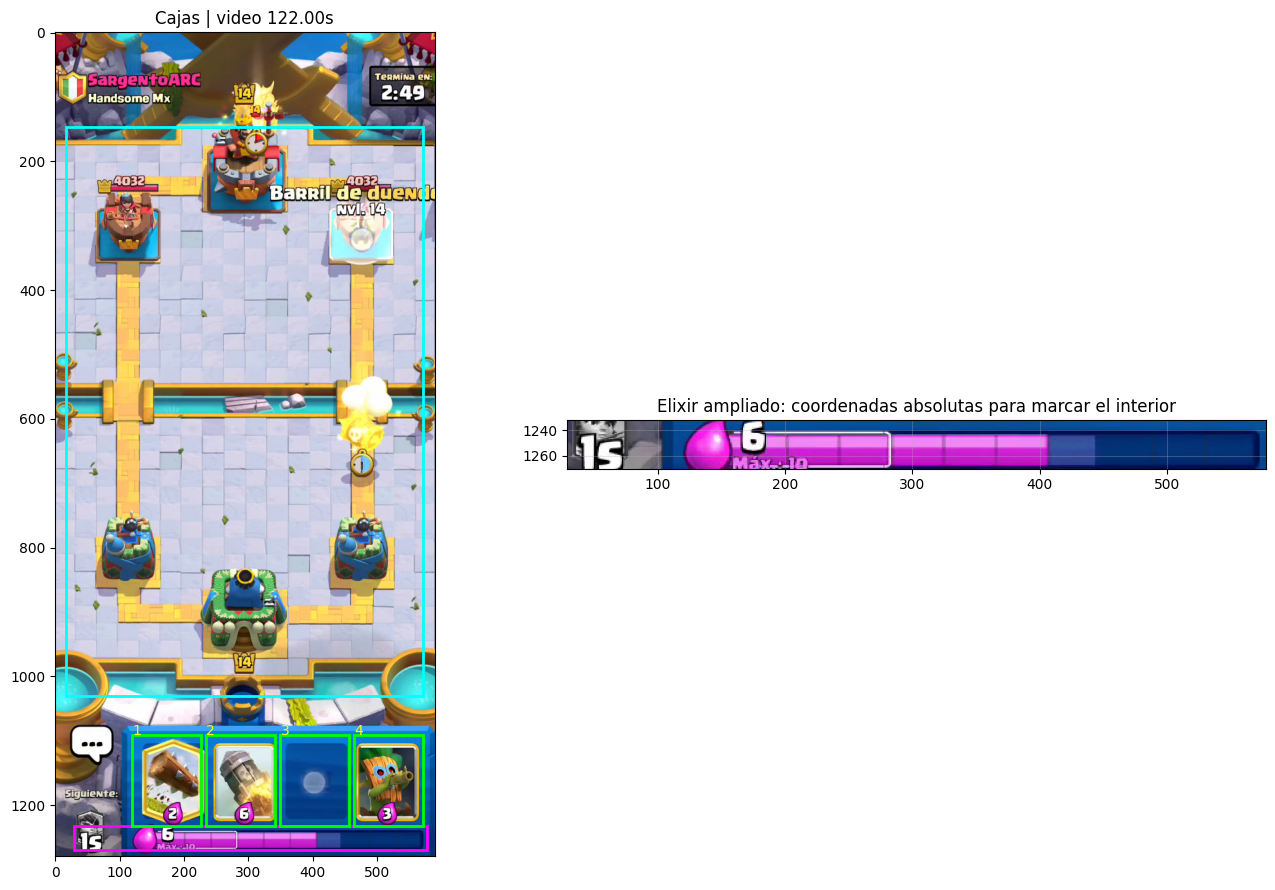

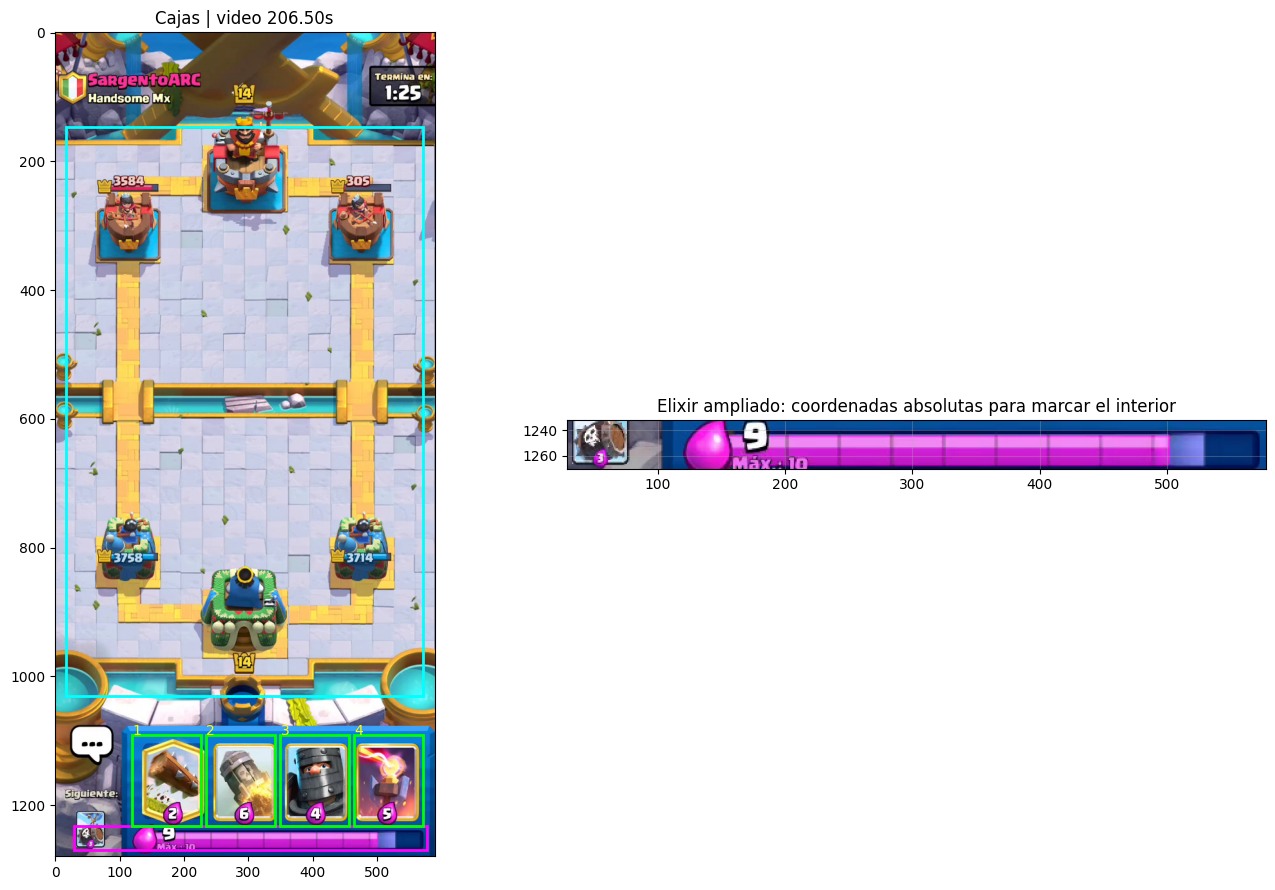

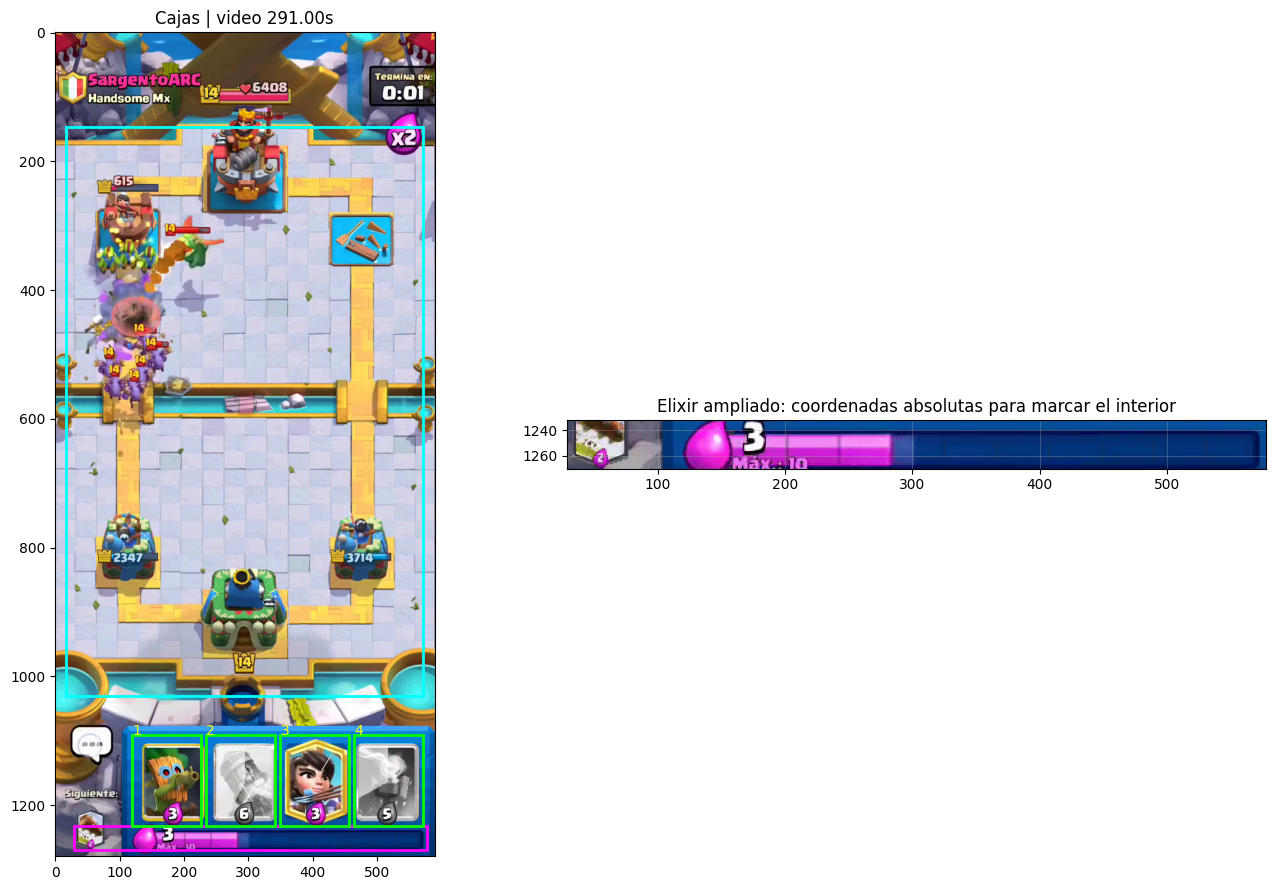

In [ ]:
def show_layout(t):
    frame = read_frame(t)
    fig, axes = plt.subplots(1, 2, figsize=(14, 9))
    axes[0].imshow(frame)
    colors = {'arena_box': 'cyan', 'elixir_bar_box': 'magenta'}
    for key, color in colors.items():
        x,y,w,h = BOXES[key]
        axes[0].add_patch(plt.Rectangle((x,y), w,h, fill=False, edgecolor=color, linewidth=2))
    for i, box in enumerate(BOXES['card_slots'], 1):
        x,y,w,h = box
        axes[0].add_patch(plt.Rectangle((x,y),w,h,fill=False,edgecolor='lime',linewidth=2))
        axes[0].text(x,y,str(i),color='yellow')
    axes[0].set_title(f'Cajas | video {t:.2f}s')
    x,y,w,h = BOXES['elixir_bar_box']
    axes[1].imshow(crop(frame, [x,y,w,h]), extent=(x,x+w,y+h,y))
    axes[1].set_title('Elixir ampliado: coordenadas absolutas para marcar el interior')
    axes[1].grid(alpha=.3)
    plt.tight_layout()
    plt.show()

for t in np.linspace(START+min(8., (END-START)/4), END-min(2., (END-START)/4), 3):
    show_layout(float(t))

## Motor integrado (no requiere edición)
Esta celda define las cuatro partes del pipeline y la persistencia local de revisiones. Ejecutarla una vez por kernel. El código usa los tiempos de presentación que informa OpenCV; si el backend no puede proporcionarlos, bloquea la lectura en lugar de inventar tiempos a partir del FPS medio.

In [ ]:
"""Extracción asistida de jugadas. Solo lecturas remotas y escrituras locales.

Los clasificadores y localizadores producen propuestas. Únicamente una revisión
humana explícita puede generar muestras exportables. CPU; sin entrenamiento.
"""
from __future__ import annotations
import csv
import hashlib
import json
import math
import os
import re
import shutil
import tempfile
import time
from dataclasses import asdict, dataclass
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PIPELINE_VERSION = '4B-local-review-2.0'


def digest(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, ensure_ascii=False,
                                    allow_nan=False).encode()).hexdigest()[:20]


def file_sha256(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()


def atomic_json(path, data):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + '.tmp')
    temporary.write_text(json.dumps(data, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')
    temporary.replace(path)


def checked_box(box, shape):
    if len(box) != 4 or any(not np.isfinite(v) for v in box):
        raise ValueError('Caja XYWH inválida.')
    x, y, w, h = map(int, box)
    ih, iw = shape[:2]
    if min(x, y) < 0 or min(w, h) <= 0 or x+w > iw or y+h > ih:
        raise ValueError(f'Caja XYWH {box} fuera de imagen {iw}x{ih}.')
    return x, y, w, h


def crop(frame, box):
    x, y, w, h = checked_box(box, frame.shape)
    return frame[y:y+h, x:x+w]


@dataclass(frozen=True)
class Parameters:
    scan_fps: float = 10.
    hsv_low: tuple = (125, 65, 60)
    hsv_high: tuple = (179, 255, 255)
    column_min: float = .35
    primary_drop: float = 1.5
    small_drop: float = .55
    descent_step: float = .12
    max_drop_window: float = .5
    slot_change: float = .10
    slot_margin: float = .025
    chat_blue: float = .50
    decision_offset: float = .7
    canonical_size: tuple = (640, 1280)  # ancho, alto; conserva proporciones con letterbox
    river_y: float = .50
    bridge_depth: float = .28
    king_depth: float = .85
    center_left: float = .36
    center_right: float = .64
    card_min_score: float = .72
    card_margin: float = .06
    max_duration_sec: float | None = None

    def validate(self):
        if not 10 <= self.scan_fps <= 60:
            raise ValueError('Usar 10–60 muestras/s para detectar combos.')
        if not .5 <= self.decision_offset <= .8:
            raise ValueError('El frame de decisión debe preceder t_drop entre 0.5 y 0.8 s.')
        if not 0 < self.small_drop <= self.primary_drop or self.descent_step <= 0:
            raise ValueError('Umbrales de caída inválidos.')
        if not 0 < self.max_drop_window <= .5:
            raise ValueError('Ventana de caída: como máximo 0.5 s.')
        if not 0 < self.river_y < 1 or not 0 < self.bridge_depth < self.king_depth < 1:
            raise ValueError('Divisiones de zona inválidas.')
        if not 0 < self.center_left < self.center_right < 1:
            raise ValueError('Divisiones horizontales inválidas.')
        if any(int(v) != v or v <= 0 for v in self.canonical_size):
            raise ValueError('Tamaño canónico inválido.')
        if self.max_duration_sec is not None and self.max_duration_sec <= 0:
            raise ValueError('La duración de diagnóstico debe ser positiva.')


class Video:
    """Tiempos absolutos del MP4. END es exclusivo; se informa tiempo real del frame."""
    def __init__(self, path, start, end):
        self.path = Path(path)
        self.start, self.end = float(start), float(end)
        cap = cv2.VideoCapture(str(path))
        try:
            ok, frame = cap.read()
            self.fps = float(cap.get(cv2.CAP_PROP_FPS))
            self.count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
            if not ok or not np.isfinite(self.fps) or self.fps <= 0 or self.count <= 0:
                raise ValueError('No se puede decodificar el MP4 o sus metadatos son inválidos.')
            self.height, self.width = frame.shape[:2]
        finally:
            cap.release()
        if not 0 <= self.start < self.end <= self.count/self.fps + 1e-6:
            raise ValueError('Segmento fuera de la duración del video.')
        self.source_hash = file_sha256(path)

    def frame(self, timestamp):
        if not np.isfinite(timestamp) or not self.start <= timestamp < self.end:
            raise ValueError(f'Frame {timestamp} fuera de [{self.start}, {self.end}).')
        cap = cv2.VideoCapture(str(self.path))
        try:
            if not cap.set(cv2.CAP_PROP_POS_MSEC, timestamp*1000):
                raise RuntimeError('El decodificador no admite búsqueda temporal.')
            ok, bgr = cap.read()
            actual = float(cap.get(cv2.CAP_PROP_POS_MSEC))/1000
            if not ok or not np.isfinite(actual) or (actual == 0 and timestamp > 2/self.fps):
                raise RuntimeError('El backend no informa tiempos de presentación. No estimar tiempos finales solo con FPS.')
            if not self.start <= actual < self.end or abs(actual-timestamp) > 2/self.fps:
                raise RuntimeError('El frame leído no coincide con la partida/tiempo solicitado.')
            return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB), actual
        finally:
            cap.release()

    def sequence(self, a, b, fps):
        """Decodificación secuencial con PTS del backend; compatible con tiempos no uniformes."""
        if not self.start <= a < b <= self.end or not 0 < fps <= self.fps:
            raise ValueError('Intervalo/frecuencia de lectura inválidos.')
        next_t = a
        cap = cv2.VideoCapture(str(self.path))
        try:
            cap.set(cv2.CAP_PROP_POS_MSEC, a*1000)
            previous = -np.inf
            while True:
                ok, frame = cap.read()
                if not ok:
                    if previous < b-2/self.fps:
                        raise RuntimeError('Lectura interrumpida; no aceptar un análisis parcial como completo.')
                    break
                t = float(cap.get(cv2.CAP_PROP_POS_MSEC))/1000
                if not np.isfinite(t) or t <= previous:
                    raise RuntimeError('Timestamps de presentación ausentes/no crecientes; revisar el backend de video.')
                previous = t
                if t >= b: break
                if t < a: continue
                if t+1e-8 >= next_t:
                    yield t, cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                    # Evitar ráfagas de recuperación si el video tiene saltos de timestamps.
                    next_t = max(next_t + 1/fps, t + .5/fps)
        finally:
            cap.release()


def elixir_signal(rgb, params):
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    mask = cv2.inRange(hsv, np.array(params.hsv_low), np.array(params.hsv_high)) > 0
    columns = mask.mean(axis=0) >= params.column_min
    pieces = np.array_split(columns, min(100, len(columns)))
    return float(10*np.mean([part.mean() >= .5 for part in pieces])), mask


def descriptor(rgb):
    h, w = rgb.shape[:2]
    center = rgb[int(.18*h):max(int(.8*h), int(.18*h)+1),
                 int(.1*w):max(int(.9*w), int(.1*w)+1)]
    return cv2.resize(center, (32, 40), interpolation=cv2.INTER_AREA).astype(np.float32)/255


def aligned_distance(a, b):
    """Compara ilustraciones tolerando elevación vertical por selección."""
    scores = []
    h = a.shape[0]
    for shift in range(-8, 9, 2):
        if shift >= 0:
            aa, bb = a[:h-shift or h], b[shift:]
        else:
            aa, bb = a[-shift:], b[:h+shift]
        scores.append(np.abs(aa-bb).mean())
    return float(min(scores))


def blue_fraction(rgb):
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    return float((cv2.inRange(hsv, np.array([90,70,35]), np.array([125,255,255])) > 0).mean())


def white_selection(rgb):
    h = max(1, int(rgb.shape[0]*.3))
    area = rgb[:h]
    return float(((area.min(axis=2) > 195) & (np.ptp(area.astype(float), axis=2) < 45)).mean())


def zone_for(coord, p):
    x, y = map(float, coord)
    if not 0 <= x <= 1 or not 0 <= y <= 1:
        raise ValueError('Coordenadas de arena fuera de [0,1].')
    if y < p.river_y:
        return None  # hechizos/minero/etc.: requieren texto manual; no asignar zona propia
    depth = (y-p.river_y)/(1-p.river_y)
    if depth >= p.king_depth:
        return 'Detrás de la torre del rey'
    if depth < p.bridge_depth:
        return 'Detrás del puente izquierdo' if x < .5 else 'Detrás del puente derecho'
    if p.center_left <= x <= p.center_right:
        return 'Centro del campo propio'
    return 'Frente a la torre izquierda' if x < .5 else 'Frente a la torre derecha'


def letterbox(rgb, size):
    width, height = map(int, size)
    h, w = rgb.shape[:2]
    scale = min(width/w, height/h)
    rw, rh = max(1, round(w*scale)), max(1, round(h*scale))
    canvas = np.zeros((height, width, 3), dtype=np.uint8)
    x, y = (width-rw)//2, (height-rh)//2
    canvas[y:y+rh, x:x+rw] = cv2.resize(rgb, (rw,rh), interpolation=cv2.INTER_AREA)
    return canvas, {'scale':scale, 'offset_xy':[x,y], 'source_size':[w,h], 'canvas_size':[width,height]}


class CardBank:
    """Banco extensible: varias referencias por carta/variante, con etiquetas humanas.

    No considera un banco de pocas cartas como catálogo completo. El matching no
    confirma evoluciones si falta referencia; la revisión de variante es obligatoria.
    """
    def __init__(self, root):
        self.root = Path(root)
        self.root.mkdir(parents=True, exist_ok=True)
        self.index_path = self.root/'templates.json'
        self.entries = json.loads(self.index_path.read_text()) if self.index_path.exists() else []
        self._cache = {}

    @property
    def fingerprint(self):
        # El hash incluye bytes de las referencias, no solo nombres de archivo.
        return digest([dict(e, bytes_sha=file_sha256(self.root/e['image'])) for e in self.entries])

    def add(self, image, name, cost, variant, kind, provenance):
        if not str(name).strip() or variant not in {'normal','evolved','unknown'}:
            raise ValueError('Nombre y variante válidos obligatorios.')
        if kind not in {'troop','building','spell','unknown'} or int(cost) != cost or not 0 <= cost <= 10:
            raise ValueError('Tipo o coste inválido. Costes especiales deben revisarse manualmente.')
        if not str(provenance).strip():
            raise ValueError('Registrar procedencia de la plantilla.')
        key = digest({'name':name.strip(),'variant':variant,'kind':kind,'cost':int(cost),
                      'pixels':hashlib.sha256(image.tobytes()).hexdigest()})
        path = self.root/f'{key}.png'
        if not cv2.imwrite(str(path), cv2.cvtColor(image, cv2.COLOR_RGB2BGR)):
            raise OSError('No se pudo escribir plantilla.')
        entry = {'key':key,'name_es':name.strip(),'cost':int(cost),'variant':variant,
                 'kind':kind,'image':path.name,'provenance':str(provenance)}
        self.entries = [e for e in self.entries if e['key'] != key] + [entry]
        atomic_json(self.index_path, self.entries)
        self._cache.clear()
        return entry

    def import_csv(self, path):
        """CSV: name_es,cost,variant,kind,image_path,provenance. Solo archivos locales."""
        frame = pd.read_csv(path, keep_default_na=False)
        required = {'name_es','cost','variant','kind','image_path','provenance'}
        if not required <= set(frame.columns):
            raise ValueError(f'El CSV necesita columnas {sorted(required)}')
        imported=[]
        for row in frame.to_dict('records'):
            image_path = Path(row['image_path'])
            if not image_path.is_absolute():
                image_path = Path(path).parent/image_path
            bgr = cv2.imread(str(image_path))
            if bgr is None:
                raise ValueError(f'No se pudo abrir referencia: {image_path.name}')
            imported.append(self.add(cv2.cvtColor(bgr,cv2.COLOR_BGR2RGB), row['name_es'],
                                     float(row['cost']),row['variant'],row['kind'],row['provenance']))
        return imported

    def rank(self, rgb, p):
        target = descriptor(rgb)
        matches=[]
        for e in self.entries:
            if e['key'] not in self._cache:
                ref = cv2.imread(str(self.root/e['image']))
                if ref is None:
                    raise ValueError('Referencia del banco ausente o ilegible.')
                self._cache[e['key']] = descriptor(cv2.cvtColor(ref,cv2.COLOR_BGR2RGB))
            ref = self._cache[e['key']]
            distance = aligned_distance(target,ref)
            # Distancia RGB y correlación estructural. Score heurístico, NO probabilidad.
            a = cv2.cvtColor(target,cv2.COLOR_RGB2GRAY).ravel()
            b = cv2.cvtColor(ref,cv2.COLOR_RGB2GRAY).ravel()
            corr = float(np.corrcoef(a,b)[0,1]) if min(a.std(),b.std()) > 1e-6 else 0.
            score = .75*(1-distance) + .25*max(0.,corr)
            matches.append(dict(e,score=float(score)))
        matches.sort(key=lambda e:e['score'],reverse=True)
        # Varias plantillas de la misma identidad no deben suprimir la segunda alternativa.
        identities={}
        for e in matches:
            identities.setdefault((e['name_es'],e['variant']),e)
        return sorted(identities.values(),key=lambda e:e['score'],reverse=True)


class ActionPipeline:
    """Pipeline local de propuestas, revisión y exportación. Sin API de subida."""
    def __init__(self, video_path, video_id, match, match_position, layout, bar_track,
                 output_root, bank_root, params=None):
        self.p = params or Parameters()
        self.p.validate()
        if not re.fullmatch(r'[A-Za-z0-9_-]+',video_id):
            raise ValueError('video_id inválido.')
        self.video_id, self.match, self.match_position = video_id, dict(match), int(match_position)
        self.video = Video(video_path, match['start_sec'],match['end_sec'])
        if self.video.fps < self.p.scan_fps:
            raise ValueError('El muestreo supera los FPS nativos.')
        if list(layout['resolution']) != [self.video.width,self.video.height]:
            raise ValueError('Resolución del video distinta de la calibración.')
        self.boxes = json.loads(json.dumps(layout['boxes_pixel']))
        if len(self.boxes['card_slots']) != 4:
            raise ValueError('Se necesitan cuatro slots.')
        for box in [self.boxes['arena_box'],self.boxes['elixir_bar_box'],*self.boxes['card_slots']]:
            checked_box(box,(self.video.height,self.video.width))
        self.bar = list(checked_box(bar_track,(self.video.height,self.video.width)))
        ex,ey,ew,eh=self.boxes['elixir_bar_box']; x,y,w,h=self.bar
        if not (ex<=x and ey<=y and x+w<=ex+ew and y+h<=ey+eh):
            raise ValueError('Interior de barra fuera de su caja general.')
        self.bank=CardBank(bank_root)
        self.config={'version':PIPELINE_VERSION,'video_id':video_id,'match':self.match,
                     'match_position':self.match_position,'video_sha256':self.video.source_hash,
                     'boxes':self.boxes,'bar':self.bar,'params':asdict(self.p)}
        self.run_id=digest(self.config)
        self.root=Path(output_root)/video_id/f'match_{self.match_position:02d}'/self.run_id
        self.root.mkdir(parents=True,exist_ok=True)
        atomic_json(self.root/'run_config.json',self.config)
        self.review_path=self.root/'review.json'
        self.reviews=json.loads(self.review_path.read_text()) if self.review_path.exists() else {}
        self.audit_path=self.root/'audited_intervals.json'
        self.audits=json.loads(self.audit_path.read_text()) if self.audit_path.exists() else []
        self.events=[]
        self.preview_tokens=set()
        self.loaded_bank_hash=self.bank.fingerprint
        self.layout_approved=False
        self.zones_approved=False
        self.signals=None
        self.hand=None
        self._scanned_identity=None

    def approve_layout(self, token):
        if token != self.run_id:
            raise ValueError('Token de layout desactualizado. Revisa el plot actual.')
        self.layout_approved=True

    def plot_layout(self, timestamp=None):
        t=timestamp if timestamp is not None else min(self.video.start+8,self.video.end-.5)
        frame,actual=self.video.frame(t)
        fig=plt.figure(figsize=(15,10))
        gs=fig.add_gridspec(3,2,width_ratios=[1,1.6],height_ratios=[3,1,1])
        ax=fig.add_subplot(gs[:,0]); ax.imshow(frame)
        for key,color in [('arena_box','cyan'),('elixir_bar_box','magenta')]:
            x,y,w,h=self.boxes[key]; ax.add_patch(plt.Rectangle((x,y),w,h,fill=False,color=color,lw=2))
        for i,box in enumerate(self.boxes['card_slots'],1):
            x,y,w,h=box;ax.add_patch(plt.Rectangle((x,y),w,h,fill=False,color='lime'))
            ax.text(x,y,str(i),color='yellow')
        ax.set_title(f'{self.video_id} | {actual:.3f}s')
        x,y,w,h=self.boxes['elixir_bar_box']
        ax=fig.add_subplot(gs[0,1]);ax.imshow(crop(frame,[x,y,w,h]),extent=(x,x+w,y+h,y),aspect='auto')
        bx,by,bw,bh=self.bar;ax.add_patch(plt.Rectangle((bx,by),bw,bh,fill=False,color='lime',lw=2))
        ax.set_title('Caja completa y franja interior: coordenadas absolutas')
        bar=crop(frame,self.bar);value,mask=elixir_signal(bar,self.p)
        ax=fig.add_subplot(gs[1,1]);ax.imshow(bar,aspect='auto');ax.set_title(f'Interior: estimación {value:.2f}/10')
        ax=fig.add_subplot(gs[2,1]);ax.imshow(mask,cmap='gray',aspect='auto');ax.set_title('Máscara magenta; contrastar con número del juego')
        fig.suptitle(f'REVISIÓN MANUAL DE CAJAS | token {self.run_id}')
        fig.tight_layout();return fig

    def plot_zones(self,timestamp=None):
        frame,_=self.video.frame(timestamp or min(self.video.start+8,self.video.end-.5))
        image=crop(frame,self.boxes['arena_box'])
        fig,ax=plt.subplots(figsize=(7,10));ax.imshow(image,extent=(0,1,1,0))
        ry=self.p.river_y; near=ry+(1-ry)*self.p.bridge_depth; ky=ry+(1-ry)*self.p.king_depth
        for y in [ry,near,ky]:ax.axhline(y,color='yellow',lw=2)
        ax.plot([.5,.5],[ry,near],color='yellow')
        for x in [self.p.center_left,self.p.center_right]:ax.plot([x,x],[near,ky],color='yellow')
        for xy,txt in [((.25,(ry+near)/2),'1 · Puente izq.'),((.75,(ry+near)/2),'2 · Puente der.'),
                       ((.17,(near+ky)/2),'3 · Torre izq.'),((.83,(near+ky)/2),'4 · Torre der.'),
                       ((.5,(near+ky)/2),'5 · Centro'),((.5,(ky+1)/2),'6 · Detrás rey')]:
            ax.text(*xy,txt,ha='center',color='white',bbox={'facecolor':'black','alpha':.65})
        ax.set_title('Zonas PRELIMINARES: ajustar río/divisiones antes de aprobar')
        ax.set_xlabel('x normalizada');ax.set_ylabel('y normalizada')
        fig.tight_layout();return fig

    def approve_zones(self,token):
        if token!=self.run_id:raise ValueError('Revisa las zonas de esta ejecución.')
        self.zones_approved=True

    def scan(self, use_cache=True):
        if not self.layout_approved:
            raise RuntimeError('Revisar plot_layout y aprobar su token antes del escaneo.')
        cache=self.root/'scan.npz'
        stop=min(self.video.end,self.video.start+self.p.max_duration_sec) if self.p.max_duration_sec else self.video.end
        if use_cache and cache.exists():
            with np.load(cache,allow_pickle=False) as data:
                t,e,hand,blue,white=[data[k] for k in ['t','e','hand','blue','white']]
        else:
            times=[];levels=[];hands=[];blues=[];whites=[]
            for t,frame in self.video.sequence(self.video.start,stop,self.p.scan_fps):
                cards=[crop(frame,b) for b in self.boxes['card_slots']]
                times.append(t);levels.append(elixir_signal(crop(frame,self.bar),self.p)[0])
                hands.append(np.stack([descriptor(c) for c in cards]))
                blues.append([blue_fraction(c) for c in cards]);whites.append([white_selection(c) for c in cards])
                if len(times)%int(self.p.scan_fps*30)==0:
                    print(f'Escaneados {t-self.video.start:.0f}/{stop-self.video.start:.0f}s',flush=True)
            if len(times)<12:raise ValueError('Tramo demasiado corto.')
            t,e,hand,blue,white=map(np.asarray,[times,levels,hands,blues,whites])
            temp=cache.with_suffix('.tmp.npz');np.savez_compressed(temp,t=t,e=e,hand=hand,blue=blue,white=white);temp.replace(cache)
        self.hand=hand
        self.signals=pd.DataFrame({'timestamp_sec':t,'elixir':e,'chat':(blue>=self.p.chat_blue).all(axis=1)})
        for i in range(4):
            self.signals[f'blue_{i+1}']=blue[:,i];self.signals[f'white_{i+1}']=white[:,i]
        self._scanned_identity=self.run_id
        print(f'{len(t)} muestras. Candidatos de chat: {int(self.signals.chat.sum())}. Pendiente de revisión.')
        return self.signals

    def _assert_scanned(self):
        if self.signals is None or self._scanned_identity!=self.run_id:
            raise RuntimeError('Ejecuta scan() para esta configuración.')

    def _chat_between(self,a,b):
        self._assert_scanned()
        s=self.signals
        # Incluir una muestra vecina a cada límite para no omitir oclusiones de borde.
        mask=s.timestamp_sec.between(a-1/self.p.scan_fps,b+1/self.p.scan_fps)
        return bool(s.loc[mask,'chat'].any())

    def detect(self):
        self._assert_scanned()
        t=self.signals.timestamp_sec.to_numpy();e=self.signals.elixir.to_numpy();n=len(t)
        increments=np.r_[0.,e[:-1]-e[1:]]
        active=np.flatnonzero(increments>=self.p.descent_step)
        groups=[]
        for index in active:
            if (groups and index==groups[-1][-1]+1 and
                t[index]-t[groups[-1][0]]<=self.p.max_drop_window):
                groups[-1].append(int(index))
            else:groups.append([int(index)])
        events=[]
        persistent=np.zeros((n,4));step=np.zeros((n,4))
        for i in range(1,n):
            step[i]=[aligned_distance(self.hand[i-1,k],self.hand[i,k]) for k in range(4)]
        for i,x in enumerate(t):
            pre=np.searchsorted(t,x-.8,side='right')-1;post=np.searchsorted(t,x+.5)
            if pre>=0 and post<n:
                persistent[i]=[aligned_distance(self.hand[pre,k],self.hand[post,k]) for k in range(4)]
        for group in groups:
            i=group[0];j=group[-1]
            # Caída agregada del descenso, sin volver a contar mesetas en la ventana móvil.
            drop=float(e[max(0,i-1)]-e[j])
            if drop<self.p.small_drop:continue
            strengths=persistent[i];order=np.argsort(strengths)[::-1]
            top,second=float(strengths[order[0]]),float(strengths[order[1]])
            ambiguous=top>=self.p.slot_change and top-second<self.p.slot_margin
            slot=int(order[0])+1 if top>=self.p.slot_change and not ambiguous else None
            label='doble_señal' if slot else ('slot_ambiguo' if ambiguous else 'revisar_caida')
            events.append(self._new_event(float(t[i]),drop,slot,label,'play_candidate',
                                         {'native_interval':[float(t[max(0,i-1)]),float(t[j])],
                                          'slot_scores':strengths.tolist(),'low_cost':drop<self.p.primary_drop}))
        # Selección sin gasto: diagnóstico separado; no es un despliegue exportable automático.
        last=-np.inf
        for i in range(1,n):
            strength=float(step[i].max())
            if strength<self.p.slot_change or t[i]-last<.5:continue
            if any(abs(ev['timestamp_sec']-t[i])<=.5 for ev in events):continue
            last=t[i]
            events.append(self._new_event(float(t[i]),0.,int(step[i].argmax())+1,
                                         'seleccion_sin_gasto','selection_diagnostic',{}))
        # Mantener eventos agregados manualmente, sin sustituir decisiones de revisión antiguas.
        manual_path=self.root/'manual_events.json'
        manual=json.loads(manual_path.read_text()) if manual_path.exists() else []
        self.events=sorted(events+manual,key=lambda ev:ev['timestamp_sec'])
        if len({ev['candidate_id'] for ev in self.events})!=len(self.events):
            raise ValueError('IDs duplicados; revisar eventos manuales.')
        self.signals['drop_step']=increments
        for k in range(4):self.signals[f'slot_{k+1}_change']=step[:,k]
        self.signals.to_csv(self.root/'signals.csv',index=False)
        atomic_json(self.root/'candidates.json',self.events)
        pd.DataFrame(self.events).to_csv(self.root/'candidates.csv',index=False)
        return self.table()

    def _new_event(self,t,drop,slot,label,event_type,extra):
        ident=digest({'run':self.run_id,'t':round(t,6),'type':event_type,'slot':slot})
        return {'candidate_id':ident,'timestamp_sec':float(t),'relative_sec':float(t-self.video.start),
                'drop_estimate':float(drop),'slot_candidate':slot,'signal':label,'event_type':event_type,
                'occluded':self._chat_between(max(self.video.start,t-.8),min(self.video.end,t+.5)),
                'review_status':'pending',**extra}

    def table(self, include_selections=False):
        rows=[]
        for event in self.events:
            if not include_selections and event['event_type']=='selection_diagnostic':continue
            row=dict(event);record=self.reviews.get(event['candidate_id'],{})
            row['review_status']=record.get('decision','pending') if self._review_current(record) else 'pending'
            rows.append(row)
        return pd.DataFrame(rows)

    def _get_event(self,event_id):
        return next(e for e in self.events if e['candidate_id']==event_id)

    def add_manual_event(self,t,slot=None,notes=''):
        if not self.video.start<=t<self.video.end:raise ValueError('Tiempo fuera de partida.')
        if slot is not None and slot not in [1,2,3,4]:raise ValueError('Slot 1–4.')
        event=self._new_event(float(t),0.,slot,'manual','manual_play',{'notes':str(notes)})
        path=self.root/'manual_events.json'
        items=json.loads(path.read_text()) if path.exists() else []
        if any(e['candidate_id']==event['candidate_id'] for e in self.events):raise ValueError('Evento duplicado.')
        items.append(event);atomic_json(path,items)
        self.events=sorted(self.events+[event],key=lambda e:e['timestamp_sec'])
        return event['candidate_id']

    def refine_time(self,event_id):
        ev=self._get_event(event_id);t=ev['timestamp_sec']
        a=max(self.video.start,t-.3);b=min(self.video.end,t+.5)
        rows=[]
        for ts,frame in self.video.sequence(a,b,self.video.fps):
            rows.append({'timestamp_sec':ts,'elixir':elixir_signal(crop(frame,self.bar),self.p)[0]})
        frame=pd.DataFrame(rows);frame['descent']=frame.elixir.shift()-frame.elixir
        if len(frame)>1 and frame.descent.max()>.05:
            # Propuesta: primer descenso sustancial a frecuencia nativa, no instante confirmado.
            onset=frame[frame.descent>.05].iloc[0].timestamp_sec
        else:onset=t
        return float(onset),frame

    def capture_template(self,t,slot,name,cost,variant='unknown',kind='unknown'):
        if slot not in [1,2,3,4]:raise ValueError('Slot 1–4.')
        frame,actual=self.video.frame(t)
        entry=self.bank.add(crop(frame,self.boxes['card_slots'][slot-1]),name,cost,variant,kind,
                            f'{self.video_id}:frame={actual:.6f}:slot={slot}; etiqueta humana')
        self.loaded_bank_hash=self.bank.fingerprint
        self.preview_tokens.clear()  # modificar referencias invalida previews/aceptaciones anteriores
        return entry

    def identify(self,event,t=None,slot=None):
        ts=float(event['timestamp_sec'] if t is None else t)
        slot=event.get('slot_candidate') if slot is None else slot
        if slot is not None and np.isfinite(slot): slot=int(slot)
        if slot not in [1,2,3,4] or ts-.8<self.video.start:
            return {'state':'slot_o_historia_insuficiente','alternatives':[]}
        frame,actual=self.video.frame(ts-.8)
        image=crop(frame,self.boxes['card_slots'][slot-1]);ranks=self.bank.rank(image,self.p)
        if not ranks:return {'state':'banco_vacio','alternatives':[],'slot_image':image}
        first=ranks[0];margin=first['score']-ranks[1]['score'] if len(ranks)>1 else 0.
        accepted=first['score']>=self.p.card_min_score and margin>=self.p.card_margin
        difference=abs(first['cost']-float(event['drop_estimate']))
        # Regeneración y combos pueden alterar el gasto aparente; no descartar silenciosamente.
        return {'state':'propuesta' if accepted else 'ambiguo','name_es':first['name_es'],
                'cost':first['cost'],'variant':first['variant'],'kind':first['kind'],
                'score':first['score'],'margin':margin,'cost_consistent':difference<=1.,
                'reference':first['image'],'source_time':actual,'alternatives':ranks[:4], 'slot_image':image}

    def locate(self,t,kind='unknown'):
        if not self.video.start<=t-.3<t+.3<self.video.end:
            return {'state':'borde_partida','proposals':[]}
        before,_=self.video.frame(t-.3);after,_=self.video.frame(t+.3)
        a,b=crop(before,self.boxes['arena_box']),crop(after,self.boxes['arena_box'])
        gray=cv2.cvtColor(cv2.absdiff(a,b),cv2.COLOR_RGB2GRAY)
        gray=cv2.GaussianBlur(gray,(5,5),0)
        # Cambios en toda la arena; para tropas priorizar campo propio. Hechizos: ambos campos.
        threshold=max(22.,float(np.percentile(gray,88)))
        mask=(gray>threshold).astype(np.uint8)*255
        kernel=np.ones((3,3),np.uint8)
        mask=cv2.morphologyEx(mask,cv2.MORPH_OPEN,kernel)
        mask=cv2.morphologyEx(mask,cv2.MORPH_CLOSE,np.ones((7,7),np.uint8))
        count,labels,stats,centroids=cv2.connectedComponentsWithStats(mask)
        h,w=gray.shape;proposals=[]
        hsv=cv2.cvtColor(b,cv2.COLOR_RGB2HSV)
        bright=((hsv[:,:,1]<90)&(hsv[:,:,2]>195)) | ((hsv[:,:,0]>12)&(hsv[:,:,0]<40)&(hsv[:,:,2]>165))
        for i in range(1,count):
            x,y,bw,bh,area=map(int,stats[i])
            if not max(8,h*w*.0001)<=area<=h*w*.12:continue
            cx,cy=centroids[i];coord=[float(cx/w),float(cy/h)]
            support=labels==i
            brightness=float(bright[support].mean());change=float(gray[support].mean()/255)
            own_bonus=.15 if coord[1]>=self.p.river_y and kind!='spell' else 0.
            score=change+.35*brightness+own_bonus
            proposals.append({'coord':coord,'score':score,'area':area,'box':[x,y,bw,bh],
                              'zone':zone_for(coord,self.p)})
        proposals.sort(key=lambda p:p['score'],reverse=True)
        return {'state':'propuestas_no_confirmadas' if proposals else 'sin_localizacion',
                'proposals':proposals[:5],'before':a,'after':b,'difference':gray,'mask':mask}

    def analyse(self, event_id, t=None, slot=None):
        ev=self._get_event(event_id)
        t=float(ev['timestamp_sec'] if t is None else t)
        ident=self.identify(ev,t,slot)
        location=self.locate(t,ident.get('kind','unknown'))
        return ident,location

    def plot_event(self,event_id,t=None,slot=None):
        ev=self._get_event(event_id);t=float(ev['timestamp_sec'] if t is None else t)
        fig,axes=plt.subplots(3,5,figsize=(17,9),gridspec_kw={'height_ratios':[4,1.4,.6]})
        for col,offset in enumerate([-.8,-.3,0.,.3,.6]):
            ts=t+offset
            if not self.video.start<=ts<self.video.end:
                for row in range(3):axes[row,col].axis('off')
                continue
            frame,actual=self.video.frame(ts)
            axes[0,col].imshow(crop(frame,self.boxes['arena_box']));axes[0,col].set_title(f'{offset:+.1f}s | {actual:.3f}s')
            cards=[cv2.resize(crop(frame,b),(80,100)) for b in self.boxes['card_slots']]
            axes[1,col].imshow(np.concatenate(cards,axis=1));axes[1,col].set_title('1 | 2 | 3 | 4')
            bar=crop(frame,self.bar);value,_=elixir_signal(bar,self.p)
            axes[2,col].imshow(bar,aspect='auto');axes[2,col].set_title(f'Elixir ≈ {value:.2f}')
            for row in range(3):axes[row,col].axis('off')
        fig.suptitle(f'{event_id} | {ev["signal"]} | {t:.3f}s | NO APROBADO')
        fig.tight_layout();return fig

    def plot_analysis(self,event_id,t=None,slot=None):
        ident,loc=self.analyse(event_id,t,slot)
        fig,axes=plt.subplots(2,4,figsize=(15,9))
        for ax in axes.flat:ax.axis('off')
        if 'slot_image' in ident:
            axes[0,0].imshow(ident['slot_image']);axes[0,0].set_title('Slot en t_drop−0.8 s')
        for ax,rank in zip(axes[0,1:],ident.get('alternatives',[])[:3]):
            bgr=cv2.imread(str(self.bank.root/rank['image']))
            ax.imshow(cv2.cvtColor(bgr,cv2.COLOR_BGR2RGB))
            ax.set_title(f'{rank["name_es"]}\n{rank["variant"]} | score {rank["score"]:.3f}')
        if 'before' in loc:
            for ax,key in zip(axes[1,:3],['before','after','difference']):
                ax.imshow(loc[key],cmap='inferno' if key=='difference' else None);ax.set_title(key)
            ax=axes[1,3];ax.imshow(loc['after'],extent=(0,1,1,0))
            for i,proposal in enumerate(loc['proposals'],1):
                x,y=proposal['coord'];ax.plot(x,y,'ro');ax.text(x,y,str(i),color='yellow')
            ax.set_title('Propuestas espaciales; elegir/corregir')
        fig.suptitle(f'Carta: {ident["state"]} | posición: {loc["state"]} | revisar coste y variante')
        fig.tight_layout();return fig

    def plot_timeline(self,a=None,b=None):
        self._assert_scanned();s=self.signals
        a=s.timestamp_sec.iloc[0] if a is None else a;b=s.timestamp_sec.iloc[-1] if b is None else b
        sub=s[s.timestamp_sec.between(a,b)]
        if sub.empty:raise ValueError('Ventana vacía.')
        fig,axes=plt.subplots(4,1,figsize=(16,10),sharex=True)
        axes[0].plot(sub.timestamp_sec,sub.elixir);axes[0].set_ylim(-.2,10.2);axes[0].set_ylabel('Elixir ≈')
        axes[1].plot(sub.timestamp_sec,sub.get('drop_step',pd.Series(0,index=sub.index)))
        axes[1].axhline(self.p.small_drop,color='orange',ls='--');axes[1].set_ylabel('Caída / paso')
        for k in range(1,5):axes[2].plot(sub.timestamp_sec,sub.get(f'slot_{k}_change',pd.Series(0,index=sub.index)),label=f'Slot {k}')
        axes[2].legend();axes[2].set_ylabel('Cambio alineado')
        axes[3].plot(sub.timestamp_sec,sub[[f'blue_{k}' for k in range(1,5)]].min(axis=1))
        axes[3].axhline(self.p.chat_blue,color='blue',ls='--');axes[3].set_ylabel('Azul mínimo')
        for ev in self.events:
            if a<=ev['timestamp_sec']<=b and ev['event_type']!='selection_diagnostic':
                axes[0].axvline(ev['timestamp_sec'],color='green' if ev['signal']=='doble_señal' else 'orange',alpha=.6)
        for ax in axes:
            ax.grid(alpha=.2)
            ax.fill_between(sub.timestamp_sec,0,1,where=sub.chat.to_numpy(),transform=ax.get_xaxis_transform(),color='blue',alpha=.1)
        axes[-1].set_xlabel('Segundos absolutos del MP4');fig.tight_layout();return fig

    def plot_audit(self,a,b,step=.5):
        if not self.video.start<=a<b<=self.video.end or step<=0:raise ValueError('Ventana inválida.')
        times=np.arange(a,b,step)
        if len(times)>24:raise ValueError('Usa páginas de 24 imágenes como máximo.')
        fig,axes=plt.subplots(math.ceil(len(times)/4),4,figsize=(14,math.ceil(len(times)/4)*5),squeeze=False)
        for ax,t in zip(axes.flat,times):
            frame,actual=self.video.frame(float(t));ax.imshow(frame);ax.set_title(f'{actual:.3f}s');ax.axis('off')
        for ax in list(axes.flat)[len(times):]:ax.axis('off')
        fig.tight_layout();return fig

    def _review_context(self):
        # Configuración, banco actual y versiones de código impiden heredar aprobaciones obsoletas.
        return digest({'run':self.run_id,'bank':self.bank.fingerprint,'version':PIPELINE_VERSION})

    def _review_current(self,record):
        return bool(record) and record.get('context')==self._review_context()

    def _payload(self,event_id,t,slot,name,cost,variant,kind,coord,zone_text='',notes=''):
        ev=self._get_event(event_id)
        if not np.isfinite(t) or not self.video.start<=t<self.video.end:raise ValueError('Tiempo inválido.')
        if ev['event_type']=='wait_candidate':
            return {'candidate_id':event_id,'action_type':'wait','timestamp_sec':float(t),
                    'hand_slot':None,'card_name':None,'elixir_cost':None,'variant':None,
                    'kind':None,'placement_coord':None,'placement_zone':None,'notes':str(notes)}
        if not np.isfinite(t) or not self.video.start<=t<self.video.end:raise ValueError('Tiempo inválido.')
        if slot not in [1,2,3,4]:raise ValueError('Seleccionar slot 1–4.')
        if name is None or not str(name).strip() or str(name).strip().lower() in {'unknown','desconocida','pendiente'}:
            raise ValueError('Identificar la carta antes de aprobar.')
        if cost is None or not np.isfinite(cost) or int(cost)!=cost or not 0<=cost<=10:
            raise ValueError('Confirmar el coste entero 0–10.')
        if variant not in {'normal','evolved'}:raise ValueError('Confirmar variante normal o evolved.')
        if kind not in {'troop','building','spell'}:raise ValueError('Confirmar tipo de carta.')
        if coord is None or len(coord)!=2 or not all(np.isfinite(c) for c in coord):
            raise ValueError('Confirmar coordenada normalizada [x,y].')
        coord=list(map(float,coord));zone=zone_for(coord,self.p)
        if zone is None:
            if not str(zone_text).strip():raise ValueError('Fuera del campo propio: escribir zona explícita para esta acción.')
            zone=str(zone_text).strip()
        return {'candidate_id':event_id,'action_type':'play','timestamp_sec':float(t),'hand_slot':int(slot),
                'card_name':str(name).strip(),'elixir_cost':int(cost),'variant':variant,'kind':kind,
                'placement_coord':coord,'placement_zone':zone,'notes':str(notes)}

    def _input_frames(self,payload):
        t=payload['timestamp_sec']
        current=t-self.p.decision_offset if payload['action_type']=='play' else t
        frames=[];times=[]
        for back in [6.,4.,2.,0.]:
            image,actual=self.video.frame(current-back)
            if payload['action_type']=='play' and back==0. and not .5-1e-8<=t-actual<=.8+1e-8:
                raise ValueError('El frame real no cumple separación 0.5–0.8s respecto a t_drop.')
            if self._chat_between(actual,actual):raise ValueError('Posible chat en una imagen de entrada; revisar antes de exportar.')
            frames.append(image);times.append(float(actual))
        if not all(a<b for a,b in zip(times,times[1:])):raise ValueError('Frames repetidos o desordenados.')
        return frames,times

    def _sample_token(self,payload,frames,times):
        return digest({'context':self._review_context(),'payload':payload,'actual_frames':times,
                       'image_pixels':[hashlib.sha256(f.tobytes()).hexdigest() for f in frames]})

    def preview_sample(self,event_id,t,slot=None,name='',cost=None,variant='unknown',kind='unknown',
                       coord=None,zone_text='',notes=''):
        if not self.layout_approved or not self.zones_approved:raise RuntimeError('Revisar cajas y zonas antes de aprobar muestras.')
        payload=self._payload(event_id,t,slot,name,cost,variant,kind,coord,zone_text,notes)
        frames,times=self._input_frames(payload)
        token=self._sample_token(payload,frames,times)
        self.preview_tokens.add(token)
        fig,axes=plt.subplots(1,4,figsize=(15,8))
        for ax,frame,actual in zip(axes,frames,times):
            ax.imshow(frame);ax.set_title(f'Entrada: {actual:.3f}s');ax.axis('off')
        text='esperar' if payload['action_type']=='wait' else f'Juega {payload["card_name"]} {payload["placement_zone"][0].lower()+payload["placement_zone"][1:]}.'
        fig.suptitle(f'REVISAR LOS 4 FRAMES · objetivo: {text}\nToken de muestra: {token}')
        fig.tight_layout(rect=[0,0,1,.90]);return fig,payload,token

    def save_review(self,payload,decision,preview_token='',checks=None,reviewer=''):
        if decision not in {'accepted','rejected','pending'}:raise ValueError('Estado inválido.')
        event=self._get_event(payload['candidate_id'])
        checks=checks or {}
        if not str(reviewer).strip():raise ValueError('Indicar nombre/iniciales de quien revisa.')
        if decision=='accepted':
            # Revalidar campos para impedir bypass mediante un diccionario incompleto/editado.
            canonical=self._payload(payload['candidate_id'],payload['timestamp_sec'],payload.get('hand_slot'),
                                    payload.get('card_name'),payload.get('elixir_cost'),payload.get('variant'),
                                    payload.get('kind'),payload.get('placement_coord'),
                                    payload.get('placement_zone',''),payload.get('notes',''))
            if canonical!=payload:raise ValueError('Payload alterado; volver a previsualizar.')
            frames,times=self._input_frames(payload)
            expected=self._sample_token(payload,frames,times)
            if expected!=preview_token or preview_token not in self.preview_tokens:
                raise RuntimeError('Mostrar los cuatro frames actuales antes de aprobar. Cambiar datos invalida el token.')
            required={'timing','card','placement','frames'} if payload['action_type']=='play' else {'stable','strategy','frames'}
            if not all(checks.get(k) is True for k in required):
                raise RuntimeError(f'Faltan comprobaciones humanas: {sorted(required)}')
            if payload['action_type']=='wait' and not self.wait_valid(payload['timestamp_sec']):
                raise ValueError('Espera sin intervalo auditado/estable o con evento cercano.')
            if event.get('occluded'):
                raise ValueError('Candidato cercano a chat: revisar el detector/cajas y regenerar antes de aceptar.')
        record={'context':self._review_context(),'decision':decision,'payload':payload,
                'preview_token':preview_token,'checks':checks,'reviewer':str(reviewer).strip(),
                'reviewed_at':time.strftime('%Y-%m-%dT%H:%M:%SZ',time.gmtime())}
        self.reviews[payload['candidate_id']]=record;atomic_json(self.review_path,self.reviews)
        self._write_review_csv()
        return record

    def reject(self,event_id,notes,reviewer):
        event=self._get_event(event_id)
        return self.save_review({'candidate_id':event_id,'timestamp_sec':event['timestamp_sec'],
                                 'notes':str(notes)},'rejected',reviewer=reviewer)

    def _write_review_csv(self):
        rows=[]
        for key,record in self.reviews.items():
            rows.append(dict(record['payload'],decision=record['decision'],reviewer=record['reviewer'],
                             context=record['context'],current=self._review_current(record)))
        pd.DataFrame(rows).to_csv(self.root/'manual_review.csv',index=False)

    def accepted(self, action_type=None):
        ids={e['candidate_id'] for e in self.events}
        result=[r for key,r in self.reviews.items() if key in ids and self._review_current(r)
                and r['decision']=='accepted']
        if action_type:result=[r for r in result if r['payload']['action_type']==action_type]
        return result

    def mark_audited(self,a,b,reviewer,notes='',confirmed_all_actions=False):
        self._assert_scanned()
        if confirmed_all_actions is not True or not str(reviewer).strip():
            raise ValueError('Confirmar explícitamente que se revisaron todas las acciones y omisiones de la ventana.')
        scanned_end=min(self.video.end,float(self.signals.timestamp_sec.iloc[-1])+1/self.p.scan_fps)
        if not self.video.start<=a<b<=scanned_end+1e-6:raise ValueError('Ventana fuera del tramo analizado.')
        # No basta revisar únicamente doble_señal; las omisiones se buscan en el video.
        pending=[]
        for ev in self.events:
            if ev['event_type']=='wait_candidate' or not a<=ev['timestamp_sec']<=b:continue
            record=self.reviews.get(ev['candidate_id'],{})
            if not self._review_current(record) or record.get('decision') not in {'accepted','rejected'}:
                pending.append(ev['candidate_id'])
        if pending:raise ValueError(f'Hay {len(pending)} candidatos sin resolver en la ventana; ejemplo {pending[:3]}.')
        self.audits.append({'context':self._review_context(),'start':float(a),'end':float(b),
                            'reviewer':str(reviewer),'notes':str(notes),'all_actions_reviewed':True})
        atomic_json(self.audit_path,self.audits)

    def covered(self,a,b):
        spans=sorted((r['start'],r['end']) for r in self.audits if r['context']==self._review_context())
        end=a
        for x,y in spans:
            if x>end+1e-6:break
            if y>=end:end=max(end,y)
            if end>=b-1e-6:return True
        return False

    def wait_valid(self,t):
        a,b=t-1.5,t+1.5
        if t-6<self.video.start or b>=self.video.end or not self.covered(a,b):return False
        if self._chat_between(t-6,b):return False
        for ev in self.events:
            if ev['event_type']=='wait_candidate':continue
            record=self.reviews.get(ev['candidate_id'],{})
            if self._review_current(record) and record.get('decision')=='rejected':continue
            et=record['payload']['timestamp_sec'] if self._review_current(record) and record.get('decision')=='accepted' else ev['timestamp_sec']
            if a<=et<=b:return False
        # Sin cambios de mano bruscos en el intervalo estable; revisar todavía su sentido estratégico.
        s=self.signals[self.signals.timestamp_sec.between(a,b)]
        keys=[f'slot_{k}_change' for k in range(1,5)]
        return not s.empty and float(s[keys].max().max())<self.p.slot_change

    def generate_waits(self,spacing=3.):
        if spacing<3.:raise ValueError('Separación de esperas mínima 3 s.')
        new=[]
        for t in np.arange(self.video.start+6,self.video.end-1.5,spacing):
            if self.wait_valid(float(t)):
                ev=self._new_event(float(t),0.,None,'espera_por_revisar','wait_candidate',{})
                if not any(x['candidate_id']==ev['candidate_id'] for x in self.events):new.append(ev)
        self.events=sorted(self.events+new,key=lambda e:e['timestamp_sec'])
        atomic_json(self.root/'candidates.json',self.events)
        return pd.DataFrame(new)

    def evaluate(self,manual_truth, a,b,fully_annotated=False,tolerance=.3):
        if fully_annotated is not True:raise ValueError('Confirmar anotación manual completa de la ventana.')
        if not self.video.start<=a<b<=self.video.end or tolerance<=0:raise ValueError('Ventana/tolerancia inválida.')
        truth=np.sort(np.asarray(manual_truth,dtype=float))
        if not np.isfinite(truth).all() or any(x<a or x>b for x in truth):raise ValueError('Verdad manual fuera de ventana.')
        if len(np.unique(truth))!=len(truth):raise ValueError('Tiempos manuales duplicados.')
        pred=np.sort([e['timestamp_sec'] for e in self.events if e['event_type']=='play_candidate'
                      and not e['occluded'] and e['signal']=='doble_señal' and a<=e['timestamp_sec']<=b])
        i=j=0;errors=[]
        while i<len(pred) and j<len(truth):
            if pred[i]<truth[j]-tolerance:i+=1
            elif pred[i]>truth[j]+tolerance:j+=1
            else:errors.append(float(pred[i]-truth[j]));i+=1;j+=1
        tp=len(errors);fp=len(pred)-tp;fn=len(truth)-tp
        result={'tp':tp,'fp':fp,'fn':fn,'precision':tp/(tp+fp) if tp+fp else None,
                'recall':tp/(tp+fn) if tp+fn else None,
                'mean_absolute_timing_error_sec':float(np.mean(np.abs(errors))) if errors else None,
                'annotation_start':a,'annotation_end':b,'tolerance_sec':tolerance}
        atomic_json(self.root/'manual_evaluation.json',result);return result

    def _verify_record(self,record):
        if not self._review_current(record) or record['decision']!='accepted':raise ValueError('Revisión obsoleta/no aprobada.')
        if not self.layout_approved or not self.zones_approved:raise ValueError('Reaprobar cajas y zonas tras reiniciar.')
        payload=record['payload'];frames,times=self._input_frames(payload)
        expected=self._sample_token(payload,frames,times)
        if expected!=record['preview_token']:raise ValueError('Las imágenes o el contexto cambiaron; revisar de nuevo.')
        if payload['action_type']=='wait' and not self.wait_valid(payload['timestamp_sec']):raise ValueError('Espera invalidada por nueva información.')
        return times

    def export_local(self,output_dir=None,balanced=True):
        """Solo muestras aprobadas. Publicación atómica de un directorio NUEVO local."""
        if file_sha256(self.video.path)!=self.video.source_hash:
            raise ValueError('El video cambió desde el análisis; reiniciar la revisión.')
        plays=self.accepted('play');waits=self.accepted('wait')
        if not plays:raise ValueError('No hay despliegues aprobados. No se genera un dataset vacío.')
        for record in plays+waits:self._verify_record(record)
        plays.sort(key=lambda r:r['payload']['timestamp_sec']);waits.sort(key=lambda r:r['payload']['timestamp_sec'])
        for first,second in zip(plays,plays[1:]):
            dt=abs(first['payload']['timestamp_sec']-second['payload']['timestamp_sec'])
            same_slot=first['payload']['hand_slot']==second['payload']['hand_slot']
            if dt<1/self.video.fps-1e-6 or (same_slot and dt<.12):
                raise ValueError('Eventos de despliegue demasiado cercanos: revisar posible duplicado/combos no resueltos.')
        if balanced:
            minimum=math.ceil(len(plays)*.15/.85-1e-10);maximum=math.floor(len(plays)*.20/.80+1e-10)
            if minimum>maximum or len(waits)<minimum:
                raise ValueError(f'Balance 15–20% imposible: {len(plays)} plays, {len(waits)} waits. Revisar más muestras; no inventarlas.')
            target=min(max(round(len(plays)*.175/.825),minimum),maximum,len(waits))
            indices=np.linspace(0,len(waits)-1,target,dtype=int) if target else []
            waits=[waits[i] for i in indices]
        records=sorted(plays+waits,key=lambda r:r['payload']['timestamp_sec'])
        review_hash=digest([dict(payload=r['payload'],token=r['preview_token']) for r in records])
        final=Path(output_dir) if output_dir else self.root/f'export_{review_hash}_{"balanced" if balanced else "checkpoint"}'
        if final.exists():
            raise FileExistsError('La exportación ya existe. No se sobrescriben muestras ni revisiones.')
        final.parent.mkdir(parents=True,exist_ok=True)
        staging=Path(tempfile.mkdtemp(prefix='.building_',dir=final.parent))
        audit=[];rows=[]
        try:
            (staging/'samples').mkdir()
            for count,record in enumerate(records,1):
                payload=record['payload'];frames,actual_times=self._input_frames(payload)
                sid=f'{self.video_id}_p{self.match_position:02d}_{payload["action_type"]}_{count:05d}'
                paths=[];transforms=[];checksums=[]
                for back,image in zip([6,4,2,0],frames):
                    canonical,transform=letterbox(image,self.p.canonical_size)
                    rel=f'samples/{sid}_t-{back}s.jpg';path=staging/rel
                    if not cv2.imwrite(str(path),cv2.cvtColor(canonical,cv2.COLOR_RGB2BGR),[cv2.IMWRITE_JPEG_QUALITY,95]):
                        raise OSError('Error escribiendo imagen.')
                    paths.append(rel);transforms.append(transform);checksums.append(file_sha256(path))
                zone=payload['placement_zone']
                name=payload['card_name']
                if payload['action_type']=='play' and payload['variant']=='evolved':name=f'{name} (evolucionada)'
                target='esperar' if payload['action_type']=='wait' else f'Juega {name} {zone[0].lower()+zone[1:]}.'
                current=payload['timestamp_sec']-self.p.decision_offset if payload['action_type']=='play' else payload['timestamp_sec']
                row={'sample_id':sid,'video_id':self.video_id,
                     'match_index':self.match.get('match_index',self.match_position),
                     'timestamp_sec':float(actual_times[-1]),'frames':paths,'action_type':payload['action_type'],
                     'card_name':payload['card_name'],'elixir_cost':payload['elixir_cost'],
                     'hand_slot':payload['hand_slot'],'placement_coord':payload['placement_coord'],
                     'placement_zone':payload['placement_zone'],'target_text':target}
                rows.append(row)
                audit.append({'sample_id':sid,'candidate_id':payload['candidate_id'],
                              'match_position':self.match_position,'manifest_match_index':self.match.get('match_index'),
                              'match_bounds':[self.video.start,self.video.end],'source_fps':self.video.fps,
                              'drop_timestamp_sec':payload['timestamp_sec'] if payload['action_type']=='play' else None,
                              'decision_requested_sec':current,'frame_times_sec':actual_times,
                              'variant':payload['variant'],'kind':payload['kind'],'review':record,
                              'image_sha256':checksums,'transforms':transforms})
            with (staging/'annotations.jsonl').open('w',encoding='utf-8') as out:
                for row in rows:out.write(json.dumps(row,ensure_ascii=False,allow_nan=False)+'\n')
            atomic_json(staging/'audit.json',audit)
            atomic_json(staging/'manifest.json',{'pipeline_version':PIPELINE_VERSION,'run':self.run_id,
                        'review_context':self._review_context(),'total_samples':len(rows),
                        'plays':len(plays),'waits':len(waits),'wait_fraction':len(waits)/len(rows),
                        'balanced':balanced,'dataset_ready':balanced,'remote_upload':False,
                        'split_group':self.video_id,'source_sha256':self.video.source_hash})
            validate_export(staging)
            staging.replace(final)
        except Exception:
            shutil.rmtree(staging,ignore_errors=True);raise
        return final


def validate_export(directory):
    directory=Path(directory);manifest=json.loads((directory/'manifest.json').read_text())
    rows=[json.loads(line) for line in (directory/'annotations.jsonl').read_text().splitlines() if line.strip()]
    audit={e['sample_id']:e for e in json.loads((directory/'audit.json').read_text())}
    if not rows or len(rows)!=manifest['total_samples']:raise ValueError('Cantidad de muestras inconsistente.')
    if len({r['sample_id'] for r in rows})!=len(rows):raise ValueError('sample_id duplicado.')
    used=set()
    for row in rows:
        if len(row['frames'])!=4 or row['sample_id'] not in audit:raise ValueError('Faltan cuatro imágenes/auditoría.')
        info=audit[row['sample_id']]
        if info['review']['decision']!='accepted':raise ValueError('Muestra sin aprobación humana.')
        times=info['frame_times_sec']
        if len(times)!=4 or not all(info['match_bounds'][0]<=t<info['match_bounds'][1] for t in times):
            raise ValueError('Historia fuera de la misma partida.')
        if abs(row['timestamp_sec']-times[-1])>1e-8:
            raise ValueError('timestamp_sec debe representar el frame de decisión real.')
        payload=info['review']['payload']
        required_checks={'timing','card','placement','frames'} if row['action_type']=='play' else {'stable','strategy','frames'}
        if not all(info['review']['checks'].get(k) is True for k in required_checks):
            raise ValueError('Faltan comprobaciones humanas en la auditoría.')
        for key in ['action_type','card_name','elixir_cost','hand_slot','placement_coord','placement_zone']:
            if row[key]!=payload[key]:raise ValueError('Anotación distinta de la revisión aprobada.')
        expected_index=info['manifest_match_index'] if info['manifest_match_index'] is not None else info['match_position']
        if row['match_index']!=expected_index:raise ValueError('match_index renumerado sin autorización.')
        if row['action_type']=='play':
            name=payload['card_name']+(' (evolucionada)' if payload['variant']=='evolved' else '')
            zone=payload['placement_zone'];expected_text=f'Juega {name} {zone[0].lower()+zone[1:]}.'
        else:expected_text='esperar'
        if row['target_text']!=expected_text:raise ValueError('Texto objetivo distinto de la revisión.')
        if not all(a<b for a,b in zip(times,times[1:])):raise ValueError('Tiempos desordenados.')
        if row['action_type']=='play' and not .5-1e-8<=info['drop_timestamp_sec']-times[-1]<=.8+1e-8:
            raise ValueError('Filtración temporal: frame actual fuera de ventana predespliegue.')
        if row['action_type']=='wait' and any(row[k] is not None for k in ['card_name','elixir_cost','hand_slot','placement_coord','placement_zone']):
            raise ValueError('Campos de espera deben ser null.')
        for rel,expected in zip(row['frames'],info['image_sha256']):
            path=(directory/rel).resolve()
            if directory.resolve() not in path.parents:raise ValueError('Ruta de imagen fuera del dataset.')
            if rel in used:raise ValueError('Ruta de imagen duplicada.')
            used.add(rel)
            image=cv2.imread(str(path))
            if image is None or file_sha256(path)!=expected:raise ValueError('Imagen ausente, corrupta o modificada.')
    if manifest['balanced'] and not .15-1e-10<=sum(r['action_type']=='wait' for r in rows)/len(rows)<=.20+1e-10:
        raise ValueError('Balance fuera del 15–20%.')
    return {'valid':True,'samples':len(rows),'images':len(used)}


def consolidated_local(checkpoints,output_dir):
    """Consolidación local con balance global; mantiene grupos de video para evitar leakage de splits."""
    target=Path(output_dir)
    if target.exists():raise FileExistsError('No sobrescribir datasets existentes.')
    all_rows=[];all_audit=[];source_dirs={};seen=set();source_hashes={}
    for folder in map(Path,checkpoints):
        validate_export(folder)
        mf=json.loads((folder/'manifest.json').read_text())
        for info in json.loads((folder/'audit.json').read_text()):
            if info['sample_id'] in seen:raise ValueError('Checkpoints duplican IDs; no consolidar revisiones del mismo match.')
            seen.add(info['sample_id']);all_audit.append(info);source_dirs[info['sample_id']]=folder
        for row in [json.loads(x) for x in (folder/'annotations.jsonl').read_text().splitlines() if x.strip()]:
            all_rows.append(row)
            old=source_hashes.setdefault(row['video_id'],mf['source_sha256'])
            if old!=mf['source_sha256']:raise ValueError('Mismo video_id con bytes diferentes.')
    plays=[r for r in all_rows if r['action_type']=='play'];waits=sorted([r for r in all_rows if r['action_type']=='wait'],key=lambda r:r['sample_id'])
    lo=math.ceil(len(plays)*.15/.85-1e-10);hi=math.floor(len(plays)*.2/.8+1e-10)
    if not plays or lo>hi or len(waits)<lo:raise ValueError('Faltan esperas aprobadas para balance global 15–20%.')
    wanted=min(max(round(len(plays)*.175/.825),lo),hi,len(waits))
    selected=plays+[waits[i] for i in np.linspace(0,len(waits)-1,wanted,dtype=int)]
    ids={r['sample_id'] for r in selected};audit=[e for e in all_audit if e['sample_id'] in ids]
    # Un video completo pertenece a un solo split; no separar frames/muestras de su mismo video.
    vids=sorted({r['video_id'] for r in selected},key=lambda v:digest(v))
    split_map={v:('train' if i<max(1,int(.8*len(vids))) else 'validation' if i<max(2,int(.9*len(vids))) else 'test') for i,v in enumerate(vids)}
    # Con un solo video no hay evaluación independiente; manifest lo declara.
    target.parent.mkdir(parents=True,exist_ok=True)
    stage=Path(tempfile.mkdtemp(prefix='.consolidating_',dir=target.parent))
    try:
        for row in selected:
            for rel in row['frames']:
                dst=stage/rel;dst.parent.mkdir(parents=True,exist_ok=True);shutil.copy2(source_dirs[row['sample_id']]/rel,dst)
        with (stage/'annotations.jsonl').open('w',encoding='utf-8') as out:
            for row in selected:out.write(json.dumps(row,ensure_ascii=False)+'\n')
        atomic_json(stage/'audit.json',audit)
        atomic_json(stage/'splits.json',{'by_video':split_map,'independent_test_available':len(set(split_map.values()))==3})
        atomic_json(stage/'manifest.json',{'pipeline_version':PIPELINE_VERSION,'total_samples':len(selected),
                    'plays':len(plays),'waits':wanted,'wait_fraction':wanted/len(selected),
                    'balanced':True,'dataset_ready':True,'remote_upload':False,'source_sha256':source_hashes})
        validate_export(stage);stage.replace(target)
    except Exception:
        shutil.rmtree(stage,ignore_errors=True);raise
    return target


def process_local_jobs(jobs,bank_root,output_root):
    """Diagnósticos por video/match. Cada job necesita token de layout revisado previamente.

    Nunca aprueba eventos ni exporta muestras automáticamente. Los checkpoints de
    señales y revisiones se conservan; un fallo no cancela los demás jobs.
    """
    reports=[]
    for job in jobs:
        try:
            pipe=ActionPipeline(job['video_path'],job['video_id'],job['match'],job['match_position'],
                                job['layout'],job['bar_track'],output_root,bank_root,
                                Parameters(**job.get('parameters',{})))
            pipe.approve_layout(job['layout_approval_token'])
            pipe.scan();table=pipe.detect()
            reports.append({'video_id':job['video_id'],'match_position':job['match_position'],
                            'status':'pending_manual_review','candidates':len(table),'path':str(pipe.root)})
        except Exception as error:
            reports.append({'video_id':job.get('video_id'),'match_position':job.get('match_position'),
                            'status':'error','reason':str(error)})
    return pd.DataFrame(reports)

In [ ]:
"""Paneles opcionales ipywidgets para Kaggle/VS Code. Solo operaciones locales."""
import json
import math
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, clear_output


def template_panel(pipe):
    import ipywidgets as W
    t=W.FloatText(value=min(pipe.video.start+8,pipe.video.end-.5),description='Video (s):')
    slot=W.Dropdown(options=[1,2,3,4],description='Slot:')
    name=W.Text(description='Carta (ES):',placeholder='Nombre verificado en español')
    cost=W.BoundedIntText(min=0,max=10,value=1,description='Coste:')
    variant=W.Dropdown(options=['unknown','normal','evolved'],description='Variante:')
    kind=W.Dropdown(options=['unknown','troop','building','spell'],description='Tipo:')
    checked=W.Checkbox(value=False,description='He identificado manualmente esta referencia')
    inspect=W.Button(description='Ver mano',button_style='info')
    save=W.Button(description='Guardar referencia local',button_style='success')
    out=W.Output()
    def show(_):
        with out:
            clear_output(wait=True)
            try:
                frame,actual=pipe.video.frame(t.value)
                fig,axes=plt.subplots(1,4,figsize=(12,4))
                for i,ax in enumerate(axes):
                    ax.imshow(crop(frame,pipe.boxes['card_slots'][i]));ax.set_title(f'Slot {i+1} | {actual:.3f}s');ax.axis('off')
                plt.show();plt.close(fig)
            except Exception as error:print(str(error))
    def store(_):
        with out:
            try:
                if not checked.value:raise ValueError('Identificar manualmente la carta antes de guardar la referencia.')
                entry=pipe.capture_template(t.value,slot.value,name.value,cost.value,variant.value,kind.value)
                print('Referencia local guardada:',entry['name_es'],entry['variant'])
                print('Cambiar el banco invalida revisiones previas: completar el banco antes de aceptar muestras.')
                checked.value=False
            except Exception as error:print(str(error))
    inspect.on_click(show);save.on_click(store)
    display(W.VBox([W.HTML('<b>Banco de cartas: completar antes de revisar las jugadas.</b>'),
                    W.HBox([t,slot,inspect]),W.HBox([name,cost]),W.HBox([variant,kind]),checked,save,out]))


def review_panel(pipe):
    import ipywidgets as W
    mode=W.Dropdown(options=[('Despliegues/casos débiles','plays'),('Selecciones sin gasto','selection'),
                             ('Esperas','wait'),('Todos','all')],description='Mostrar:')
    picker=W.Dropdown(options=[],description='Evento:',layout=W.Layout(width='95%'))
    refresh=W.Button(description='Actualizar lista')
    t=W.FloatText(description='t_drop (s):')
    slot=W.Dropdown(options=[1,2,3,4],description='Slot:')
    name=W.Text(description='Carta (ES):')
    cost=W.BoundedIntText(value=1,min=0,max=10,description='Coste:')
    variant=W.Dropdown(options=['unknown','normal','evolved'],description='Variante:')
    kind=W.Dropdown(options=['unknown','troop','building','spell'],description='Tipo:')
    x=W.BoundedFloatText(min=0,max=1,step=.001,value=.5,description='Arena x:')
    y=W.BoundedFloatText(min=0,max=1,step=.001,value=.7,description='Arena y:')
    zone=W.Text(description='Zona externa:',placeholder='Solo si la posición queda en el campo rival')
    notes=W.Textarea(description='Notas:')
    reviewer=W.Text(description='Revisor/a:',placeholder='Nombre o iniciales')
    inspect=W.Button(description='1. Inspeccionar',button_style='info')
    preview=W.Button(description='2. Ver cuatro entradas',button_style='info')
    accept=W.Button(description='3. Aceptar localmente',button_style='success')
    reject=W.Button(description='Rechazar',button_style='danger')
    checks={key:W.Checkbox(value=False,description=label) for key,label in [
        ('timing','Tiempo corregido sobre el video'),('card','Carta, coste y variante verificados'),
        ('placement','Coordenada y zona verificadas'),('frames','Revisé los 4 frames: no revelan la acción'),
        ('stable','Sin jugadas durante al menos 3 s'),('strategy','Esperar es una decisión razonable aquí') ]}
    out=W.Output();saved={}
    def invalidate(change=None):
        saved.clear()
        for box in checks.values():box.value=False
    for control in [t,slot,name,cost,variant,kind,x,y,zone,notes]:control.observe(invalidate,names='value')
    def select(change=None):
        invalidate()
        if not picker.value:return
        ev=pipe._get_event(picker.value)
        t.value=ev['timestamp_sec'];slot.value=ev.get('slot_candidate') or 1
        name.value='';variant.value='unknown';kind.value='unknown';zone.value='';notes.value=''
        t.description='Decisión (s):' if ev['event_type']=='wait_candidate' else 't_drop (s):'
        waiting=ev['event_type']=='wait_candidate'
        for key in ['timing','card','placement']:checks[key].disabled=waiting
        for key in ['stable','strategy']:checks[key].disabled=not waiting
    def refresh_list(_=None):
        selected=picker.value
        items=[]
        for ev in pipe.events:
            typ=ev['event_type']
            if mode.value=='plays' and typ in {'selection_diagnostic','wait_candidate'}:continue
            if mode.value=='selection' and typ!='selection_diagnostic':continue
            if mode.value=='wait' and typ!='wait_candidate':continue
            record=pipe.reviews.get(ev['candidate_id'],{})
            status=record.get('decision','pending') if pipe._review_current(record) else 'pending'
            label=f'{ev["timestamp_sec"]:.3f}s | {ev["signal"]} | {status} | {ev["candidate_id"][:8]}'
            items.append((label,ev['candidate_id']))
        picker.options=items
        if selected in [v for _,v in items]:picker.value=selected
        else:select()
    picker.observe(select,names='value');mode.observe(refresh_list,names='value');refresh.on_click(refresh_list)
    def inspect_event(_):
        with out:
            clear_output(wait=True)
            try:
                if not picker.value:raise ValueError('No hay eventos en este filtro.')
                ev=pipe._get_event(picker.value)
                fig=pipe.plot_event(picker.value,t.value,slot.value);plt.show();plt.close(fig)
                if ev['event_type']!='wait_candidate':
                    ident,loc=pipe.analyse(picker.value,t.value,slot.value)
                    if 'name_es' in ident:
                        name.value=ident['name_es'];cost.value=ident['cost']
                        variant.value=ident['variant'];kind.value=ident['kind']
                        print('Propuesta de carta:',ident['name_es'],'|',ident['state'],
                              '| score heurístico:',round(ident['score'],3),'| coste consistente:',ident['cost_consistent'])
                    else:print('Carta sin identificar: crear referencias o completar campos manualmente.')
                    if loc['proposals']:
                        x.value,y.value=loc['proposals'][0]['coord']
                        print('Coordenada propuesta; corregir tras mirar la arena:',loc['proposals'][0])
                    fig=pipe.plot_analysis(picker.value,t.value,slot.value);plt.show();plt.close(fig)
                    proposed,curve=pipe.refine_time(picker.value)
                    fig,ax=plt.subplots(figsize=(12,3));ax.plot(curve.timestamp_sec,curve.elixir,'.-')
                    ax.axvline(proposed,color='orange',label='Inicio propuesto; confirmar manualmente')
                    ax.axvline(t.value,color='red',ls='--',label='Tiempo del formulario');ax.legend();ax.grid(alpha=.2)
                    ax.set_title('Refinamiento a frames nativos');plt.show();plt.close(fig)
                    print('Propuesta temporal:',round(proposed,6),'s. No se aplica automáticamente.')
                print('Ajusta los campos; después pulsa «Ver cuatro entradas». Aceptar nunca es automático.')
            except Exception as error:print(type(error).__name__+':',str(error))
    def preview_event(_):
        with out:
            clear_output(wait=True)
            try:
                if not picker.value:raise ValueError('Seleccionar un evento.')
                fig,payload,token=pipe.preview_sample(picker.value,t.value,slot.value,name.value,cost.value,
                                                     variant.value,kind.value,[x.value,y.value],zone.value,notes.value)
                saved.update(payload=payload,token=token)
                plt.show();plt.close(fig)
                print('Completa las comprobaciones humanas y pulsa Aceptar. No hay ninguna subida remota.')
            except Exception as error:print(type(error).__name__+':',str(error))
    def save_event(_):
        with out:
            try:
                if not saved:raise ValueError('Mostrar primero las cuatro entradas con los valores actuales.')
                pipe.save_review(saved['payload'],'accepted',saved['token'],
                                 {k:v.value for k,v in checks.items()},reviewer.value)
                print('ACEPTADO localmente:',picker.value)
                refresh_list()
            except Exception as error:print(type(error).__name__+':',str(error))
    def reject_event(_):
        with out:
            try:
                if not picker.value:raise ValueError('Seleccionar un evento.')
                if not notes.value.strip():raise ValueError('Anotar por qué se rechaza.')
                pipe.reject(picker.value,notes.value,reviewer.value)
                print('RECHAZADO localmente:',picker.value);refresh_list()
            except Exception as error:print(type(error).__name__+':',str(error))
    inspect.on_click(inspect_event);preview.on_click(preview_event);accept.on_click(save_event);reject.on_click(reject_event)
    refresh_list()
    display(W.VBox([W.HTML('<b>Revisión humana por evento. Cambiar un campo invalida el preview anterior.</b>'),
        W.HBox([mode,refresh]),picker,W.HBox([t,slot]),W.HBox([name,cost]),W.HBox([variant,kind]),
        W.HBox([x,y]),zone,notes,reviewer,W.HBox([inspect,preview]),
        W.VBox(list(checks.values())),W.HBox([accept,reject]),out]))


def audit_panel(pipe):
    import ipywidgets as W
    a=W.FloatText(value=pipe.video.start,description='Desde (s):')
    b=W.FloatText(value=min(pipe.video.end,pipe.video.start+8),description='Hasta (s):')
    step=W.BoundedFloatText(min=.05,max=2,step=.05,value=.5,description='Paso (s):')
    view=W.Button(description='Ver ventana',button_style='info')
    done=W.Checkbox(value=False,description='Revisé TODAS las acciones/omisiones de esta ventana')
    reviewer=W.Text(description='Revisor/a:');notes=W.Text(description='Notas:')
    mark=W.Button(description='Registrar intervalo auditado',button_style='success')
    manual_t=W.FloatText(value=pipe.video.start+8,description='Omitida (s):')
    manual_slot=W.Dropdown(options=[('Sin determinar',None),('1',1),('2',2),('3',3),('4',4)],description='Slot:')
    add=W.Button(description='Añadir jugada omitida')
    out=W.Output()
    def show(_):
        with out:
            clear_output(wait=True)
            try:
                fig=pipe.plot_audit(a.value,b.value,step.value);plt.show();plt.close(fig)
                print('Si observas una jugada omitida, añádela y luego revísala en el panel de eventos.')
            except Exception as error:print(str(error))
    def store(_):
        with out:
            try:
                pipe.mark_audited(a.value,b.value,reviewer.value,notes.value,done.value)
                print('Intervalo registrado:',a.value,b.value);done.value=False
            except Exception as error:print(str(error))
    def insert(_):
        with out:
            try:print('Evento añadido:',pipe.add_manual_event(manual_t.value,manual_slot.value,notes.value))
            except Exception as error:print(str(error))
    view.on_click(show);mark.on_click(store);add.on_click(insert)
    display(W.VBox([W.HTML('<b>Auditoría del video: necesaria para encontrar omisiones y generar esperas.</b>'),
                    W.HBox([a,b,step]),view,W.HBox([manual_t,manual_slot]),add,
                    done,reviewer,notes,mark,out]))

## 3. Configurar esta partida y revisar las cajas
Se conserva la franja propuesta `[160, 1257, 410, 5]` **solo para el video `4Tt7nuuy-Bg` con resolución 590×1280**. Para otros videos hay que marcar su propia franja de 0 a 10, incluyendo la parte vacía. No copiar coordenadas entre dispositivos.

Las seis zonas son una división preliminar ajustable: el río y las divisiones se dibujan sobre la arena. Los hechizos pueden colocarse en campo rival; esas posiciones necesitan texto de zona manual.

Si necesitas corregir parámetros, recrea `pipe` ejecutando esta celda y vuelve a revisar cajas/zonas. Las revisiones están vinculadas a la configuración, al video y al banco para impedir reutilizar aprobaciones desactualizadas.

In [13]:
PIPELINE_ROOT = ROOT.parent / 'action_dataset_3_1'
BANK_ROOT = PIPELINE_ROOT / 'card_bank'

if VIDEO_ID == '4Tt7nuuy-Bg' and [WIDTH, HEIGHT] == [590, 1280]:
    BAR_TRACK_XYWH = [160, 1248, 410, 5]
else:
    BAR_TRACK_XYWH = None  # Marcar [x, y, ancho, alto] usando el plot ampliado anterior.

PARAMS = Parameters(
    scan_fps=10.0,
    hsv_low=(125, 65, 60), hsv_high=(179, 255, 255), column_min=.35,
    primary_drop=1.5, small_drop=.55, slot_change=.10, slot_margin=.025,
    chat_blue=.50, decision_offset=.70,
    canonical_size=(640, 1280),
    river_y=.50, bridge_depth=.28, king_depth=.85,
    center_left=.36, center_right=.64,
    max_duration_sec=None,  # None = partida completa. Un límite produce solo diagnósticos parciales.
)
if BAR_TRACK_XYWH is None:
    raise RuntimeError('Marcar la franja interior de la barra para este video antes de continuar.')

pipe = ActionPipeline(
    video_path=VIDEO_PATH, video_id=VIDEO_ID, match=match,
    match_position=MATCH_POSITION, layout=layout, bar_track=BAR_TRACK_XYWH,
    output_root=PIPELINE_ROOT, bank_root=BANK_ROOT, params=PARAMS,
)
print('Diagnósticos y revisión locales:', pipe.root)
print('Referencias de cartas disponibles:', len(pipe.bank.entries))

Diagnósticos y revisión locales: /kaggle/working/action_dataset_3_1/4Tt7nuuy-Bg/match_00/c1808c73d8a7186c88cf
Referencias de cartas disponibles: 0


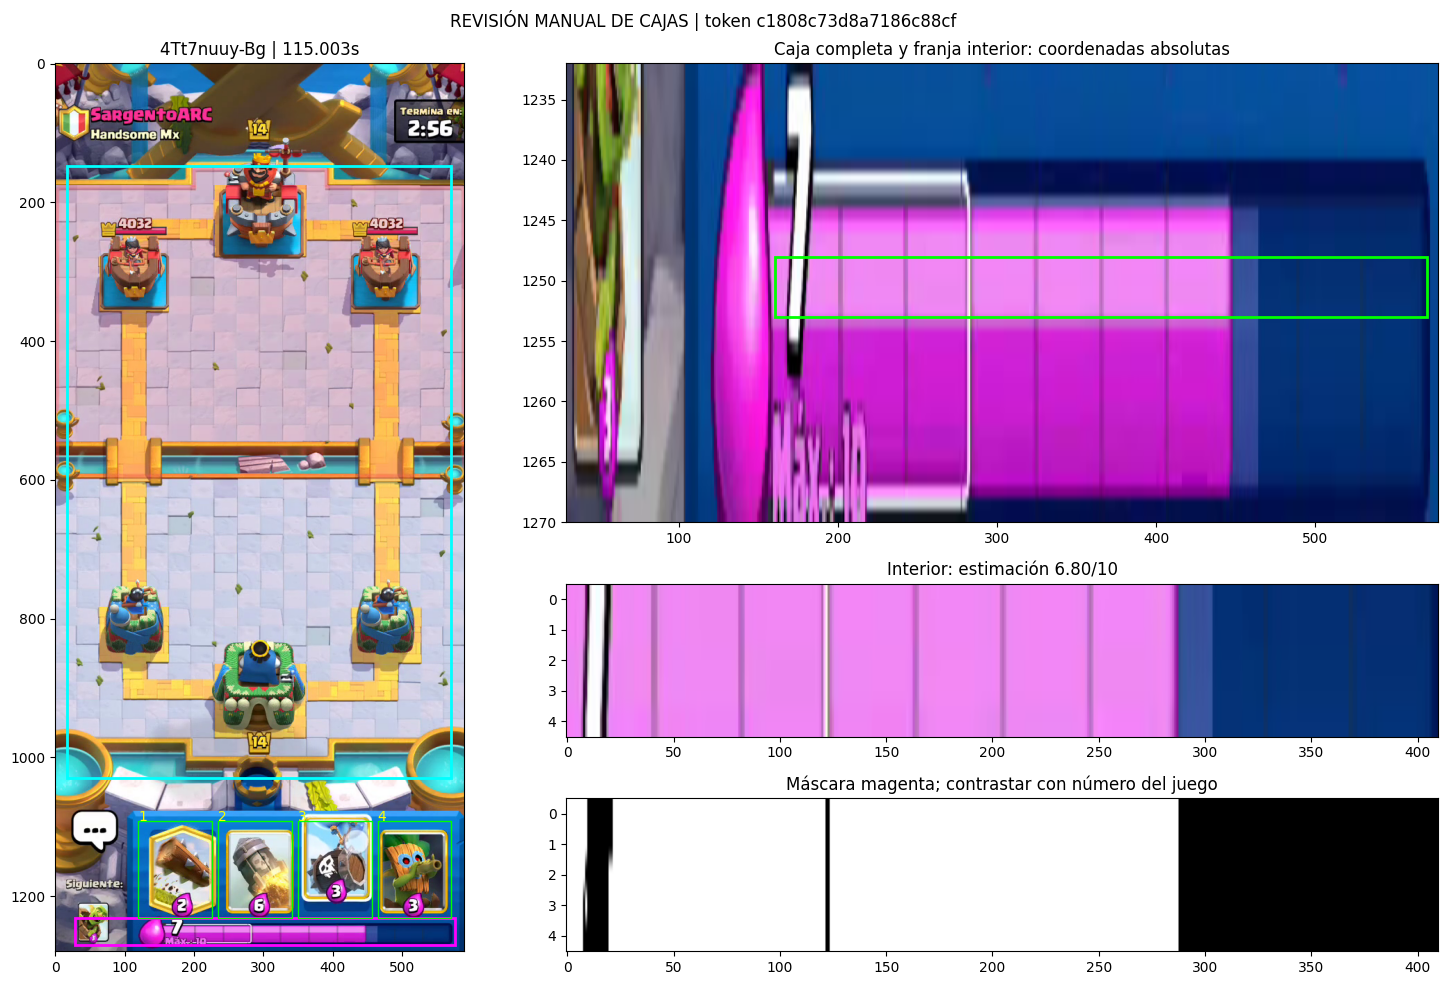

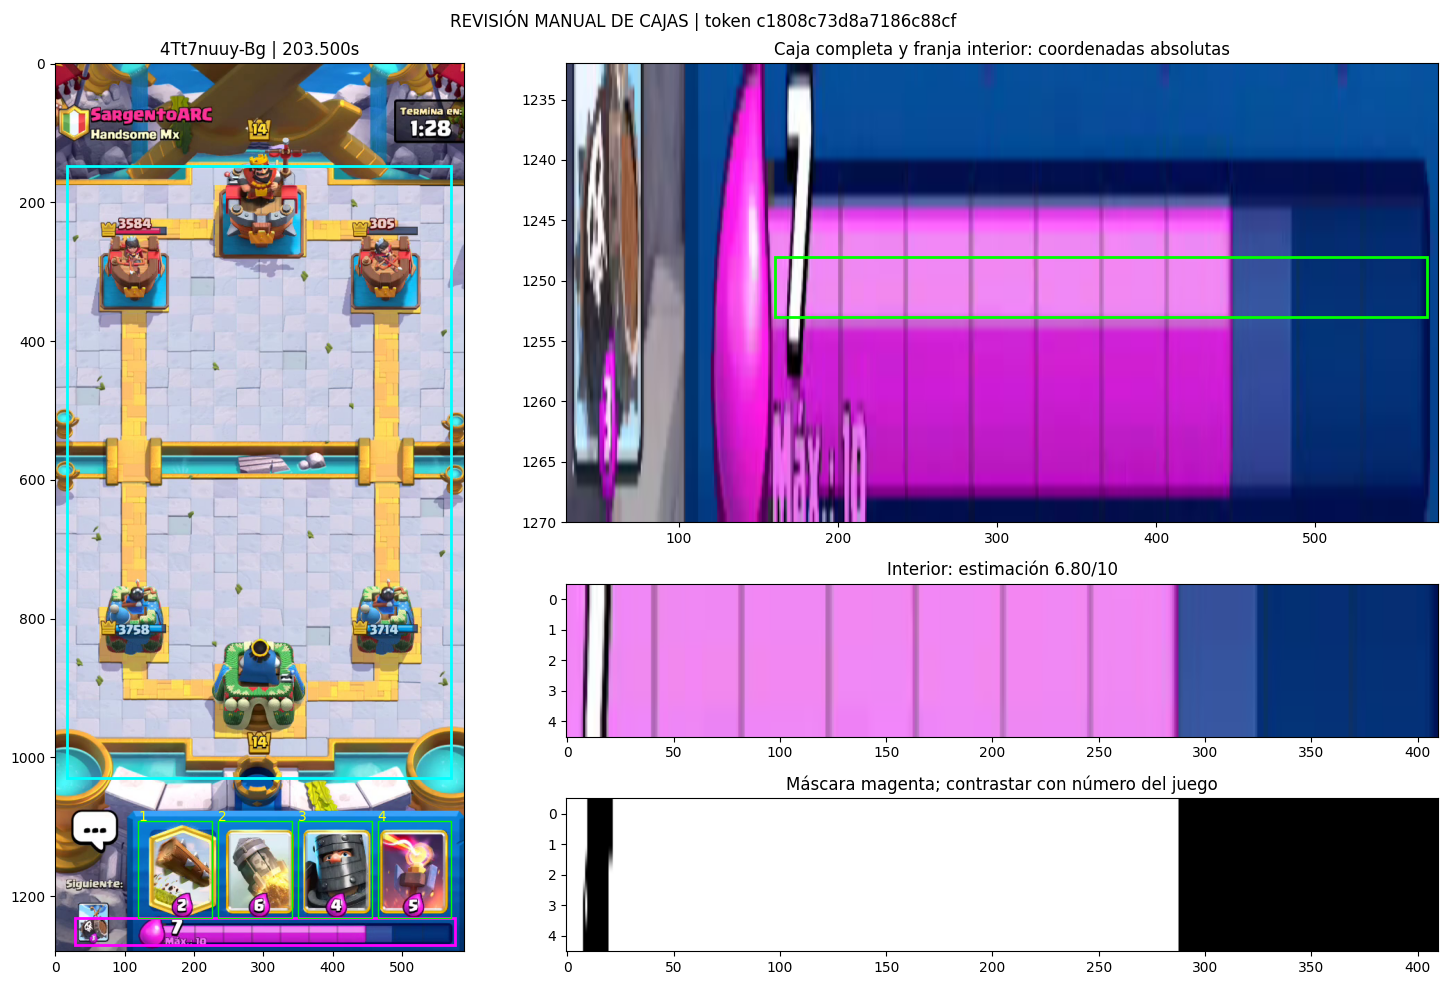

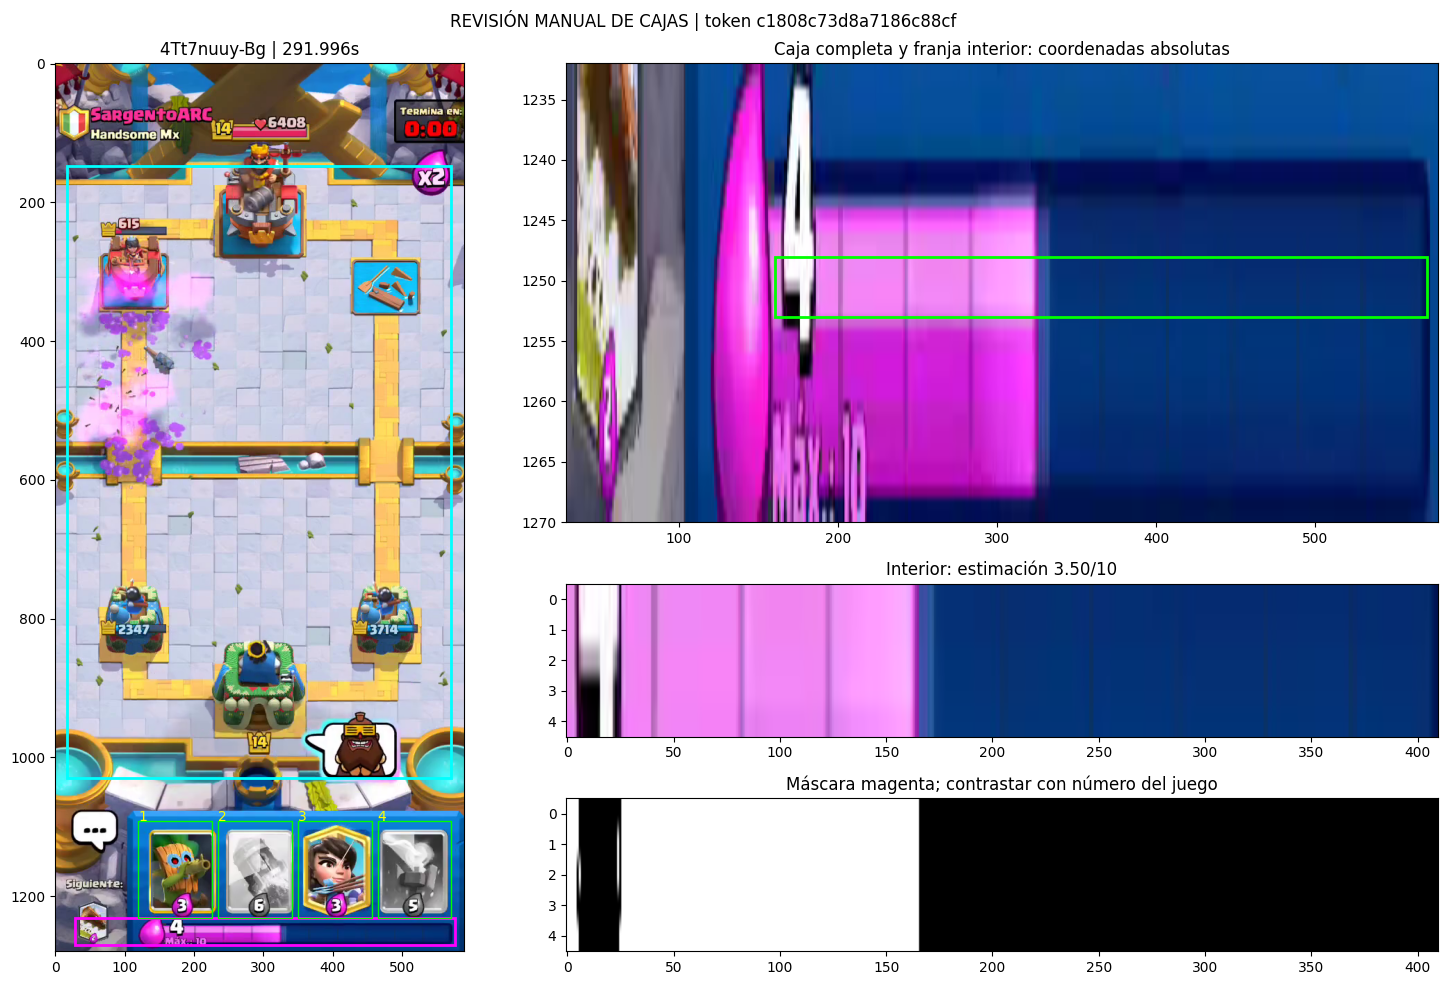

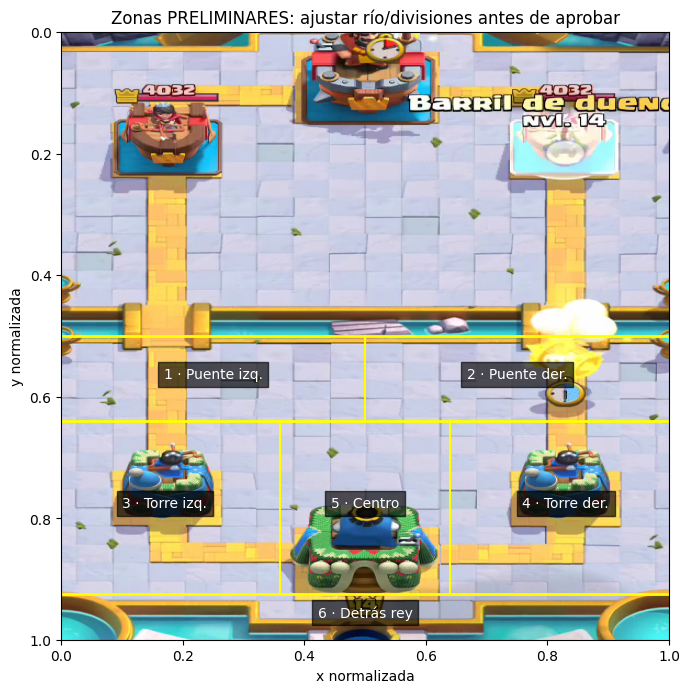

Contrasta la estimación de elixir con el número visible en los tres instantes.
Revisa también río, torres y zonas. No apruebes si las cajas o la franja cortan elementos.


In [14]:
for t in np.linspace(START + 1, END - 1, 3):
    fig = pipe.plot_layout(float(t))
    plt.show()
    plt.close(fig)
fig = pipe.plot_zones()
plt.show()
plt.close(fig)
print('Contrasta la estimación de elixir con el número visible en los tres instantes.')
print('Revisa también río, torres y zonas. No apruebes si las cajas o la franja cortan elementos.')

In [15]:
# Cambiar a True únicamente DESPUÉS de mirar los plots de esta configuración.
APPROVE_LAYOUT = True
APPROVE_ZONES = True

if APPROVE_LAYOUT:
    pipe.approve_layout(pipe.run_id)
if APPROVE_ZONES:
    pipe.approve_zones(pipe.run_id)
print('Cajas revisadas:', pipe.layout_approved, '| zonas revisadas:', pipe.zones_approved)

Cajas revisadas: True | zonas revisadas: True


## 4. Escanear, separar selecciones de despliegues y revisar la curva
Se agrupan los descensos consecutivos de elixir para evitar repetir un evento por la misma caída. Las comparaciones de slots toleran elevación vertical para reducir señales por seleccionar cartas. Los combos con descensos separados se conservan; si no se distinguen, se revisan a frames nativos o se añaden manualmente.

`doble_señal` sigue siendo una propuesta, no una aprobación. `slot_ambiguo` marca varias cartas que cambian cerca. Las selecciones sin gasto se conservan en una tabla separada para auditoría. Una caída de elixir sin despliegue también puede ser otra acción (por ejemplo, una habilidad): rechazarla si no corresponde al formato de jugar carta.

Un valor de chat igual a cero significa que la heurística no disparó, no que se haya demostrado ausencia de chat.

Escaneados 30/179s
Escaneados 60/179s
Escaneados 90/179s
Escaneados 120/179s
Escaneados 150/179s
1790 muestras. Candidatos de chat: 0. Pendiente de revisión.
Candidatos de despliegue/casos débiles: 39


,candidate_id,timestamp_sec,relative_sec,drop_estimate,slot_candidate,signal,event_type,occluded,review_status,native_interval,slot_scores,low_cost
0,03179b0bf2860201f424,120.512391,6.512391,5.4,NaN,revisar_caida,play_candidate,False,pending,"[120.41192230408573, 120.51239115874078]","[0.008881739340722561, 0.00744383130222559, 0....",False
1,5dc6411608f2d4f003cb,122.103148,8.103148,4.8,2.0,doble_señal,play_candidate,False,pending,"[122.00267916945747, 122.20361687876758]","[0.012094566598534584, 0.1611468493938446, 0.0...",False
2,108c1aa9091dfd0b782d,123.409243,9.409243,3.7,3.0,doble_señal,play_candidate,False,pending,"[123.3087742799732, 123.40924313462826]","[0.11020322889089584, 0.08158394694328308, 0.4...",False
3,c909058e8432a125be14,123.610181,9.610181,2.2,3.0,doble_señal,play_candidate,False,pending,"[123.50971198928332, 123.61018084393838]","[0.10003574192523956, 0.08290032297372818, 0.4...",False
4,fda1955e95efd031769c,134.209645,20.209645,4.9,3.0,doble_señal,play_candidate,False,pending,"[134.10917615539182, 134.20964501004687]","[0.008201593533158302, 0.1099928542971611, 0.3...",False
5,7d1b792106660537dc36,143.101139,29.101139,4.5,3.0,doble_señal,play_candidate,False,pending,"[143.00066979236436, 143.1011386470194]","[0.1831638067960739, 0.14963847398757935, 0.35...",False
6,c68c007a8e9a0e399e43,143.302076,29.302076,4.9,3.0,doble_señal,play_candidate,False,pending,"[143.2016075016745, 143.30207635632954]","[0.177933007478714, 0.15330371260643005, 0.348...",False
7,c5323293e9be7a0d84da,147.806430,33.806430,1.9,NaN,slot_ambiguo,play_candidate,False,pending,"[147.70596115204287, 147.80643000669792]","[0.0055678109638392925, 0.033930759876966476, ...",False
8,c8a2f0d3a70ab14339e8,174.112525,60.112525,5.4,4.0,doble_señal,play_candidate,False,pending,"[174.0120562625586, 174.2129939718687]","[0.136813223361969, 0.00865911040455103, 0.006...",False
9,9dc90c060f0c65a4d4df,175.301407,61.301407,5.2,1.0,doble_señal,play_candidate,False,pending,"[175.2009377093101, 175.40187541862022]","[0.34273257851600647, 0.16309334337711334, 0.0...",False


,event_type,signal,cantidad
0,play_candidate,doble_señal,30
1,play_candidate,revisar_caida,1
2,play_candidate,slot_ambiguo,8
3,selection_diagnostic,seleccion_sin_gasto,68


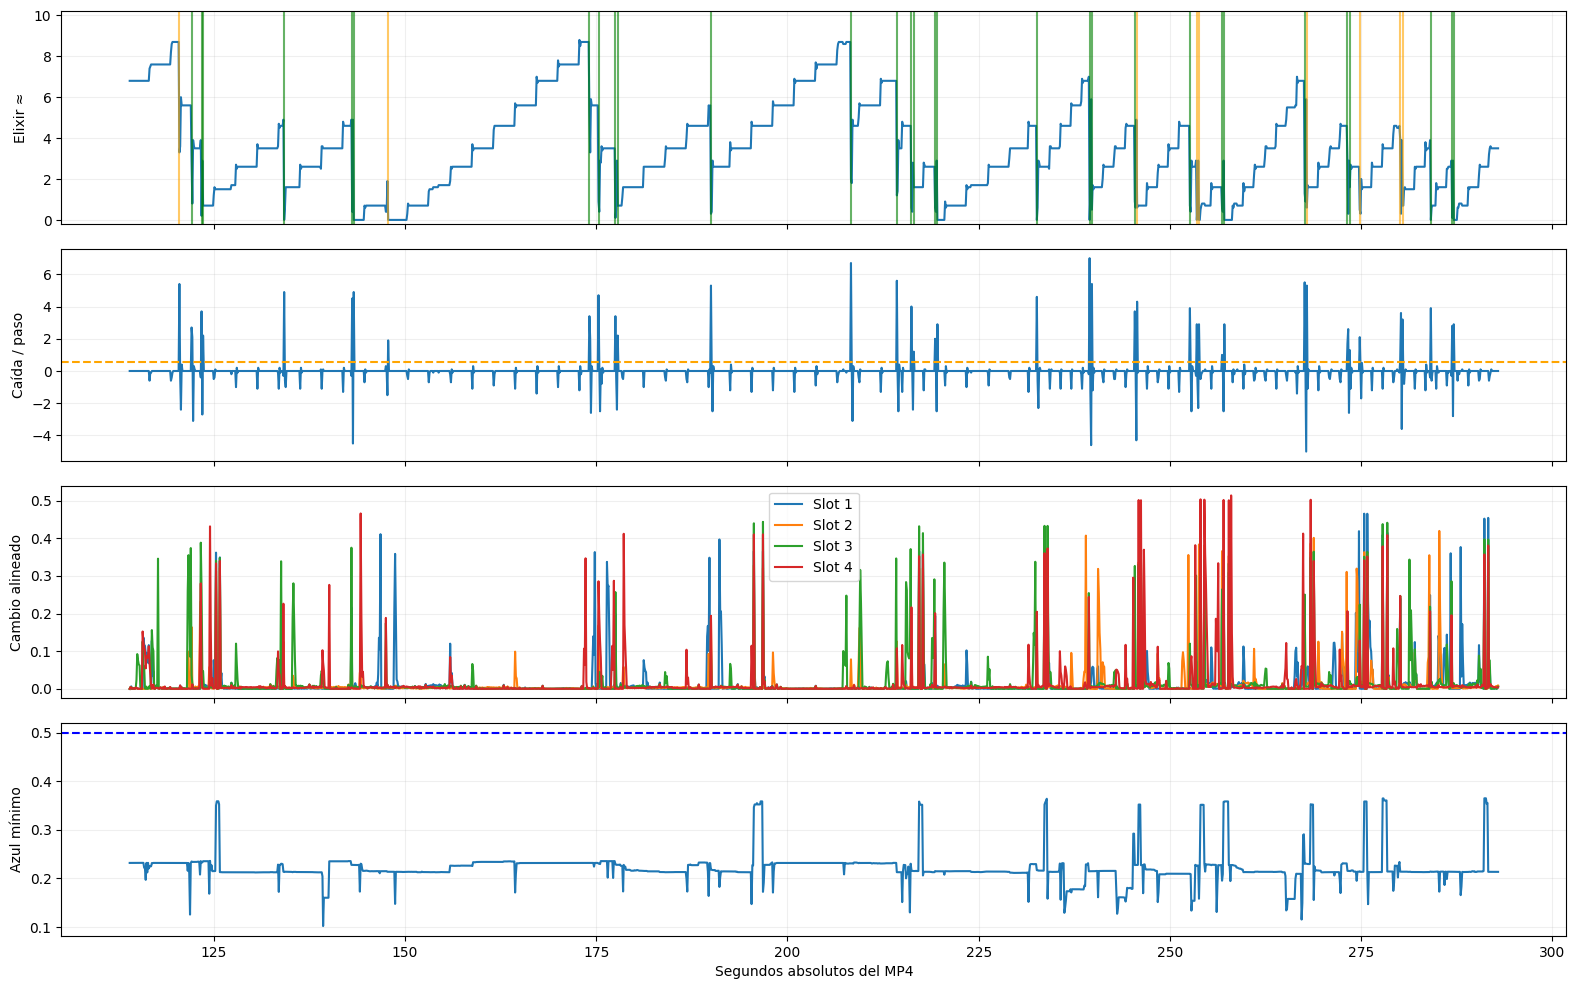

In [16]:
signals = pipe.scan(use_cache=True)
events = pipe.detect()
print('Candidatos de despliegue/casos débiles:', len(events))
display(events)
all_events = pipe.table(include_selections=True)
if not all_events.empty:
    display(all_events.groupby(['event_type', 'signal']).size().rename('cantidad').reset_index())
fig = pipe.plot_timeline()
fig.savefig(pipe.root / 'timeline.png', dpi=140, bbox_inches='tight')
plt.show()
plt.close(fig)

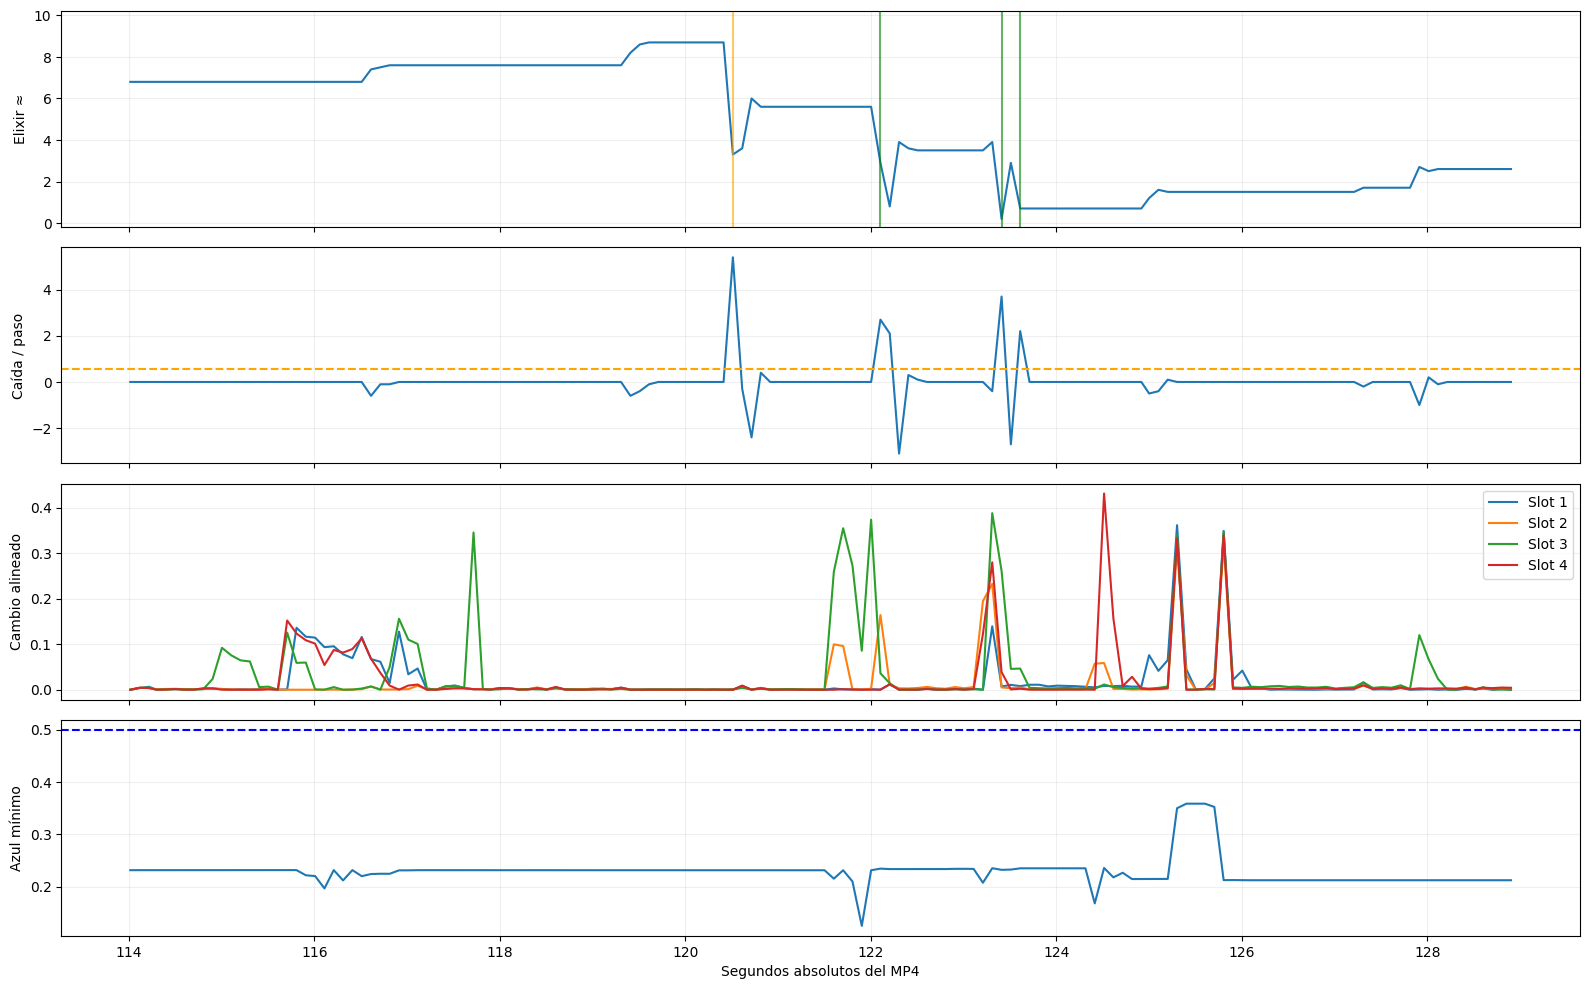

In [17]:
# Vista ampliada opcional; editar segundos absolutos del MP4.
ZOOM_START = START
ZOOM_END = min(END, START + 15)
fig = pipe.plot_timeline(ZOOM_START, ZOOM_END)
plt.show()
plt.close(fig)

## 5. Banco de cartas y evoluciones
Antes de aceptar muestras, reúne las cartas presentes en el mazo con sus nombres en español, costes, tipo y variante. En un frame de mano visible, pulsa **Ver mano**, identifica la carta y guarda la referencia local. Usa varias referencias si cambia la elevación o el aspecto.

No existe aquí un catálogo ficticio de todas las cartas: si el banco está vacío, la identificación devuelve `banco_vacio`; si hay pocas referencias o poca diferencia entre alternativas, devuelve `ambiguo`. El score es una similitud heurística, no una probabilidad de acierto. Una carta y su evolución son identidades separadas; `unknown` nunca se exporta como variante confirmada.

**Completa/importa el banco antes de aprobar jugadas**. Añadir o cambiar referencias invalida revisiones previas para que no se exporten etiquetas obtenidas con un banco distinto.

In [ ]:
try:
    template_panel(pipe)
except ImportError:
    print('Instala ipywidgets para usar botones. Alternativa mediante función:')
    print("pipe.capture_template(t=SEGUNDO, slot=1, name='Nombre en español', cost=4, variant='normal', kind='troop')")

In [ ]:
# Importación opcional de un catálogo local. Rutas accesibles en Kaggle.
# CSV requerido: name_es,cost,variant,kind,image_path,provenance
# Variantes: normal/evolved/unknown. Tipos: troop/building/spell/unknown.
# image_path debe apuntar a recortes de referencia; rutas relativas al CSV o absolutas.
CATALOG_CSV = None
if CATALOG_CSV:
    imported = pipe.bank.import_csv(CATALOG_CSV)
    pipe.preview_tokens.clear()
    print('Referencias importadas:', len(imported))
    print('Revisiones anteriores quedan desactualizadas por el nuevo banco.')
display(pd.DataFrame(pipe.bank.entries))

## 6. Revisión con botones: tiempo, carta, posición y cuatro entradas
1. Seleccionar un evento y pulsar **Inspeccionar**. Se muestra arena/mano/elixir antes y después, las referencias de cartas y las propuestas espaciales.
2. Mirar la curva a frames nativos. Corregir `t_drop` si hace falta; el refinamiento es una propuesta, no se aplica solo.
3. Confirmar/corregir slot, nombre, coste, variante y tipo de carta. Si hay duda, no aceptar.
4. Elegir coordenada normalizada mirando la arena. La diferencia visual puede corresponder a movimiento de tropas, efectos o despliegue enemigo; no asumir que el componente más grande es el correcto. Para campo rival escribir una zona explícita.
5. Pulsar **Ver cuatro entradas**, revisar las cuatro imágenes y completar las casillas humanas.
6. Aceptar localmente o rechazar con motivo. Cambiar cualquier campo invalida el preview anterior.

Los frames de entrada son −6, −4, −2 y 0 s respecto al instante de decisión, que está 0.7 s antes del despliegue corregido. Los frames posteriores solo se usan para etiquetar/revisar; nunca entran al modelo.

Las muestras al inicio de la partida sin seis segundos de historia no se exportan. No se rellena historia con frames de otra partida. Tampoco se acepta una muestra con posible oclusión sin resolver.

In [ ]:
try:
    review_panel(pipe)
except ImportError:
    print('Instala ipywidgets y vuelve a ejecutar esta celda para abrir el panel de revisión.')

### Galería por páginas (alternativa o complemento a los botones)
Cambiar página y filtro. No se ejecutan todas las páginas a la vez para evitar salidas gigantes y exceso de memoria. En la versión anterior solo se había guardado la página 0; eso no validaba los otros candidatos.

In [ ]:
PAGE = 0
PAGE_SIZE = 4
INCLUDE_SELECTIONS = False
review_table = pipe.table(include_selections=INCLUDE_SELECTIONS)
if review_table.empty:
    print('No hay eventos en este filtro.')
else:
    total_pages = math.ceil(len(review_table) / PAGE_SIZE)
    if not 0 <= PAGE < total_pages:
        raise ValueError(f'PAGE debe estar entre 0 y {total_pages - 1}.')
    print('Página', PAGE, 'de', total_pages, '| candidatos', len(review_table))
    for event_id in review_table.iloc[PAGE*PAGE_SIZE:(PAGE+1)*PAGE_SIZE].candidate_id:
        fig = pipe.plot_event(event_id)
        fig.savefig(pipe.root / f'event_{event_id}.png', dpi=120, bbox_inches='tight')
        plt.show()
        plt.close(fig)

## 7. Buscar omisiones y registrar intervalos revisados
La auditoría debe recorrer la partida, no solo las detecciones del algoritmo. El panel permite ver ventanas con paso configurable y añadir jugadas que faltan. Después de añadir una, pulsa **Actualizar lista** en el panel de revisión y resuélvela.

Para registrar una ventana como auditada, deben estar resueltos todos sus candidatos (también selecciones), y la persona revisora debe confirmar que buscó omisiones. Los intervalos auditados se guardan localmente. No se generan esperas basándose únicamente en que el detector no encontró jugadas.

In [ ]:
try:
    audit_panel(pipe)
except ImportError:
    print('Alternativa sin botones: pipe.plot_audit(inicio, fin, step=.5)')
    print('Añadir omisión: pipe.add_manual_event(t, slot=1, notes="Despliegue omitido")')
    print('Registrar auditoría: pipe.mark_audited(a, b, reviewer="Iniciales", confirmed_all_actions=True)')

## 8. Generar y revisar candidatos de espera
Requiere un intervalo auditado sin acciones durante al menos tres segundos, sin chat y sin cambios de mano bruscos. La ausencia de acciones no demuestra una decisión óptima: el revisor debe confirmar también que esperar es razonable.

Después de generar, abrir/actualizar el panel de revisión y elegir **Esperas**. Mostrar cuatro entradas y completar las casillas de estabilidad, estrategia y frames antes de aceptar.

In [ ]:
wait_candidates = pipe.generate_waits(spacing=3.0)
print('Nuevos candidatos de espera:', len(wait_candidates))
display(wait_candidates)
if wait_candidates.empty:
    print('Puede faltar auditoría o no haber ventanas estables. No se inventan muestras para completar el balance.')

In [ ]:
# Abrir de nuevo el panel si no conservas el anterior. Cambiar el filtro a Esperas.
# review_panel(pipe)
print('Despliegues aprobados:', len(pipe.accepted('play')))
print('Esperas aprobadas:', len(pipe.accepted('wait')))

## 9. Evaluación temporal contra anotación manual
Completar toda una ventana y registrar los tiempos reales, incluidas las omisiones. El evaluador compara el detector original con esa anotación, no con sus propios tiempos corregidos. Emparejamiento uno a uno: dos candidatos de una jugada no cuentan como dos aciertos.

Se permite usar la lista de despliegues aceptados como verdad manual **solo tras auditar completamente la ventana**, añadir omisiones y resolver duplicados. No se activa por defecto.

In [ ]:
FULL_MANUAL_TRUTH = False
EVAL_START = START
EVAL_END = END
MANUAL_TRUTH_CSV = None  # CSV local con columna timestamp_sec; opcional.

if not FULL_MANUAL_TRUTH:
    print('Métricas pendientes: falta confirmar anotación manual completa de la ventana.')
else:
    if not pipe.covered(EVAL_START, EVAL_END):
        raise RuntimeError('Primero registrar la auditoría completa de la ventana de evaluación.')
    if MANUAL_TRUTH_CSV:
        truth_times = pd.read_csv(MANUAL_TRUTH_CSV)['timestamp_sec'].astype(float).tolist()
    else:
        truth_times = [r['payload']['timestamp_sec'] for r in pipe.accepted('play')
                       if EVAL_START <= r['payload']['timestamp_sec'] <= EVAL_END]
    metrics = pipe.evaluate(truth_times, EVAL_START, EVAL_END, fully_annotated=True, tolerance=.3)
    display(pd.DataFrame([metrics]))

## 10. Exportación LOCAL de muestras aprobadas
La exportación verifica otra vez aprobación, imágenes, tiempos, ausencia de duplicados y balance. Genera cuatro JPEG canónicos por muestra conservando proporciones, `annotations.jsonl`, auditoría y manifiesto. `timestamp_sec` en el JSONL es el instante real del frame de decisión; `t_drop` y todos los tiempos se conservan en `audit.json`.

Conserva el `match_index` del manifiesto y añade la posición de lista en la auditoría. La variante evolucionada también se explicita en el texto objetivo. Los ejemplos de espera llevan campos de carta/posición en `null`.

Por defecto exige 15–20% de esperas aprobadas. Si no alcanza el balance, se detiene con explicación; no duplica ni inventa esperas. Una exportación sin balance se declara **checkpoint**, no dataset final, y puede consolidarse después con otras partidas.

El directorio se publica localmente solo cuando todos los archivos pasan la validación. No sobrescribe una exportación existente. **No hay subida a R2.**

In [ ]:
EXPORT_LOCAL = False  # Cambiar solo después de completar la revisión humana.
REQUIRE_BALANCE = True

if EXPORT_LOCAL:
    export_path = pipe.export_local(balanced=REQUIRE_BALANCE)
    print('Exportación local:', export_path)
    print(validate_export(export_path))
    # Empaquetado opcional para descargar desde Kaggle:
    # zip_path = shutil.make_archive(str(export_path), 'zip', root_dir=export_path)
    # print('ZIP local:', zip_path)
else:
    print('Exportación sin ejecutar. No se ha subido ningún resultado.')

## 11. Varias partidas, reanudación y balance global
El análisis por lotes solo genera diagnósticos. Cada trabajo necesita cajas/barra aprobadas para ese video y partida. Un fallo queda registrado y se continúa con los demás. Las muestras se revisan por partida.

Para reunir checkpoints locales ya aprobados, la consolidación verifica sus imágenes, rechaza IDs duplicados y selecciona esperas para balance global. Los splits se asignan **por video completo**, evitando distribuir frames vecinos del mismo video entre entrenamiento y prueba. Con pocos videos no se declara una evaluación independiente completa.

In [ ]:
# Ejemplo de estructura; no se ejecuta un lote sin trabajos configurados/revisados.
JOBS = []
# JOBS = [{
#     'video_path': str(VIDEO_PATH), 'video_id': VIDEO_ID, 'match': match,
#     'match_position': MATCH_POSITION, 'layout': layout,
#     'bar_track': BAR_TRACK_XYWH, 'parameters': asdict(PARAMS),
#     'layout_approval_token': pipe.run_id,
# }]
if JOBS:
    display(process_local_jobs(JOBS, BANK_ROOT, PIPELINE_ROOT))

CHECKPOINTS = []  # Rutas a exportaciones locales APROBADAS de partidas distintas.
CONSOLIDATE_LOCAL = False
if CONSOLIDATE_LOCAL:
    if not CHECKPOINTS:
        raise ValueError('Indicar checkpoints locales aprobados.')
    combined = consolidated_local(CHECKPOINTS, PIPELINE_ROOT / 'dataset_consolidado')
    print('Consolidación local:', combined)
    print(validate_export(combined))

## Guardado y límites de esta versión

- Guardar el `.ipynb` con Ctrl+S para conservar código y salidas. Las referencias, cachés y revisiones viven en `/kaggle/working/action_dataset_3_1`; descargar una copia antes de terminar la sesión. El notebook no incorpora automáticamente esos archivos.
- Un reinicio de kernel requiere recrear `pipe`, revisar/aprobar cajas y zonas y cargar el escaneo; las revisiones locales se recuperan si sus archivos siguen presentes y su contexto coincide.
- La identificación por plantillas y el mapa de diferencias son propuestas heurísticas. No se ha demostrado todavía su precisión en tus videos ni su capacidad de distinguir todos los hechizos/evoluciones. Rechazar o corregir ambigüedades.
- Las seis zonas son preliminares y deben coincidir visualmente con cada arena. No se asigna una zona propia a colocaciones rivales.
- Las partidas reales y los metadatos privados no se pudieron ejecutar desde el entorno de preparación: esta versión necesita ejecución y revisión visual en tu Kaggle. Las pruebas sintéticas no sustituyen esa validación.
- No hay entrenamiento, modificación de D1 ni funciones de escritura remota. La futura subida a R2 requerirá un paso distinto, después de validar los resultados.